# 1. Imports

In [85]:
import pandas as pd
import numpy as np

import boto3 # Bibliothèque Python d'AWS qui permet de faire comme aws s3 mais de récupérer le tout en données Python
from botocore import UNSIGNED # On importe des éléments du package botocore installé avec boto3 pour ne pas avoir à s'identifier
from botocore.config import Config

import os

import openslide
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

import time
from PIL import Image # bibliothèque pour manipuler des images (OpenSlide renvoie en image PIL avec read_region)

import torch
import sklearn

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

import joblib

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, accuracy_score, recall_score, precision_score

from scipy import ndimage
from scipy.spatial.distance import pdist

# 2. Première exploration du bucket AWS S3 camelyon-dataset

Les données du dataset CAMELYON17 sont stockées sur AWS qui héberge gratuitement certaines données utiles à la recherche. Le service de stockage d'AWS s'appelle S3 et est organisé en grands dossiers appelés buckets.

Nous utilisons l'outil AWS CLI, un programme AWS qui permet de consulter les données sur AWS en lignes de commandes :
- ! car le code n'est pas du Python donc à envoyer au terminal du système
- aws s3 ls : commande permettant de lister les fichiers (aws est le programme AWS CLI, s3 est le service utilisé, ls est l'action qui permet de lister le contenu).
- --no-sign-request : option permettant d'accéder aux données sans s'identifier.
- s3://camelyon-dataset/ : l'adresse comprennant le service utilisé (S3) et le nom du bucket. On pourra ensuite aller chercher dans un chemin particulier à l'intérieur du bucket. Le nom du bucket a été trouvé sur cette page : https://registry.opendata.aws/camelyon/.

In [6]:
!aws s3 ls --no-sign-request s3://camelyon-dataset/

                           PRE CAMELYON16/
                           PRE CAMELYON17/


PRE signifie prefix. C’est la façon dont S3 indique un "dossier". On observe que camelyon-dataset contient deux dossiers : CAMELYON16 et CAMELYON17. CAMELYON16 est un autre challenge, lancé avant CAMELYON17.

In [7]:
!aws s3 ls --no-sign-request s3://camelyon-dataset/CAMELYON17/ 

                           PRE annotations/
                           PRE evaluation/
                           PRE images/
                           PRE masks/
2022-09-28 11:15:29          0 
2022-09-28 14:49:30       3464 README.md
2022-09-28 14:49:33      71099 checksums.md5
2022-09-29 04:02:24       7260 license.txt
2022-09-29 04:05:37      18689 stages.csv


Le "dossier" CAMELYON17/ contient à sa racine 4 autres dossiers et 4 fichiers :
- Les dossiers :
  - images/
  - annotations/
  - masks/
  - evaluation/
- Les fichiers :
  - stages.csv
  - README.md
  - license.txt
  - checksums.md5

### 2.1. Fichier `README.md`


Nous commençons par récupérer le README afin de pouvoir le lire.

In [8]:
os.makedirs("../data/raw", exist_ok=True)
!aws s3 cp --no-sign-request s3://camelyon-dataset/CAMELYON17/README.md ../data/raw/

# cp pour copier à l'endroit indiqué

Completed 3.4 KiB/3.4 KiB (4.2 KiB/s) with 1 file(s) remaining
download: s3://camelyon-dataset/CAMELYON17/README.md to ..\data\raw\README.md


Voici ce que nous apprend le README du dataset CAMELYON17 (copié dans data/) :

- Les données :
  - 1 000 lames entières (WSI) de ganglions sentinelles, venant de 5 hopitaux aux Pays-Bas : Radboud UMC, Canisius-Wilhelmina, UMC Utrecht, Rijnstate et LabPON.
  - Les données sont réparties entre entrainement et test : 20 patientes par centre dans chaque jeu, soit 100 patientes
  (=500 lames) pour l'entraînement et 100 patientes (=500 lames) pour le test.
  - 5 lames par patiente, chaque lame provenant d'un ganglion sentinelle différent.

- Le contenu des dossiers :
  - images/ : les 1 000 lames, au format TIFF multirésolution (convertis avec le logiciel ASAP)
  - annotations/ : les contours des métastases au format XML (lisibles dans ASAP) pour 10 lames par centre, soit 50 lames, annotées de façon exhaustive. Il y a deux groupes d'annotations (attribut `PartOfGroup`) : Tumor pour les zones tumorales, Exclusion pour les zones non tumorales découpées à l'intérieur des zones "Tumor". A noter : les métastases micro et macro sont annotées de manière exhaustive mais pas les ITC. **A vérifier : les lames annotées font à priori parti du jeu d'entrainement.**
  - masks/ : des masques tout prêts pour 100 lames : les 50 lames annotées ainsi que 50 lames négatives choisies au hasard. Voici les valeurs de chaque pixel : 0 pour le fond (verre), 1 pour le tissu sain et 2 pour une tumeur. Les zones tumorales viennent des contours XML. **A vérifier : idem, il s'agirait à priori de lames du jeu d'entrainement.**

- Le contenu des fichiers :
  - stages.csv : les étiquettes avec le stade pN de chaque patiente et la classe de chaque lame
  (négative, ITC, micro, macro). **À vérifier : entraînement seulement ou aussi test ?**
  - license.txt : la licence d'utilisation.
  - checksums.md5 : les empreintes MD5 de tous les fichiers, pour vérifier qu'une lame
  téléchargée n'est pas abîmée (commande md5sum).

- La description complète du challenge peut être trouvée via ce lien : https://camelyon17.grand-challenge.org

### 2.2. Fichier `stages.csv`

Nous le copions tout d'abord tel quel dans data/raw/.

In [9]:
!aws s3 cp --no-sign-request s3://camelyon-dataset/CAMELYON17/stages.csv ../data/raw/

Completed 18.3 KiB/18.3 KiB (23.2 KiB/s) with 1 file(s) remaining
download: s3://camelyon-dataset/CAMELYON17/stages.csv to ..\data\raw\stages.csv


Nous le découvrons ensuite via pandas.

In [10]:
stages = pd.read_csv("../data/raw/stages.csv")
stages

,patient,stage,center
0,patient_000.zip,pN0,0
1,patient_000_node_0.tif,negative,0
2,patient_000_node_1.tif,negative,0
3,patient_000_node_2.tif,negative,0
4,patient_000_node_3.tif,negative,0
...,...,...,...
595,patient_099_node_0.tif,negative,4
596,patient_099_node_1.tif,negative,4
597,patient_099_node_2.tif,negative,4
598,patient_099_node_3.tif,negative,4


In [11]:
print(f"Le fichier contient {stages.shape[0]} lignes et {stages.shape[1]} colonnes.")

Le fichier contient 600 lignes et 3 colonnes.


Les 600 lignes concernent 100 patientes. Pour chaque patiente :
- 1 ligne au niveau patiente soit 100 lignes (ex : patient_000.zip où 'patient_000' identifie la patiente). Les patientes sont numérotées de 000 à 099.
- 5 lignes au niveau lame soit 5*100 = 500 lames (ex : patient_000_node_0.tif où 'patient_000' identifie la patiente et 'node_0' identifie le ganglion concerné par la lame). Les ganglions sont numérotés de 0 à 4.

Il y a 3 colonnes :
- `patient` qui est le nom du fichier qui identifie la patiente / la lame
- `stage` qui indique le stade pN pour les lignes au niveau patiente et la classe de la lame (negative, ITC, micro, macro) pour les lignes au niveau lame
- `center` qui identifie le centre médical

Il s'agit donc ici des données d'entrainement.

### 2.3. Dossier `images/`

In [12]:
s3 = boto3.client("s3", region_name="us-west-2", config=Config(signature_version=UNSIGNED)) # On crée un client = un objet qui sait parler au service S3.
BUCKET, PREFIX = "camelyon-dataset", "CAMELYON17/"

def lister(dossier):
    """Renvoie un DataFrame (fichier, taille en octets, en Mo et en Go) des fichiers d'un dossier d'AWS."""
    fichiers = []
    paginateur = s3.get_paginator("list_objects_v2") # list_objects_v2 est l’opération d’AWS qui liste des fichiers. get_paginator crée un paginateur qui permettra de demander toutes les pages une par une, si plusieurs.
    pages = paginateur.paginate(Bucket=BUCKET, Prefix=PREFIX + dossier) # .paginate() est une méthode de l’objet paginateur qui reçoit les paramètres de la requête et renvoie un objet itérable.
    for page in pages:
        for fichier in page.get("Contents", []): # Chaque page est un dictionnaire Python et la liste des fichiers est dans "Contents"
            nom = fichier["Key"].split("/")[-1] # On ne garde que le nom
            if nom:
                fichiers.append({"fichier": nom, "taille_octets": fichier["Size"], "taille_Mo": round(fichier["Size"]/1000000,2), "taille_Go": round(fichier["Size"]/1000000000,2)})
    return pd.DataFrame(fichiers)

In [13]:
images = lister("images/")

In [14]:
print(f"Le dossier images/ contient {len(images)} fichiers (attendu : un par lame (1000)).")

Le dossier images/ contient 1000 fichiers (attendu : un par lame (1000)).


In [15]:
images

,fichier,taille_octets,taille_Mo,taille_Go
0,patient_000_node_0.tif,2837938781,2837.94,2.84
1,patient_000_node_1.tif,2212330723,2212.33,2.21
2,patient_000_node_2.tif,2308484849,2308.48,2.31
3,patient_000_node_3.tif,2208844437,2208.84,2.21
4,patient_000_node_4.tif,1905999125,1906.00,1.91
...,...,...,...,...
995,patient_199_node_0.tif,2030096771,2030.10,2.03
996,patient_199_node_1.tif,5331147711,5331.15,5.33
997,patient_199_node_2.tif,4905934953,4905.93,4.91
998,patient_199_node_3.tif,8109937725,8109.94,8.11


### 2.4. Dossier `annotations/`

In [16]:
annotations = lister("annotations/")

In [17]:
print(f"Le dossier annotations/ contient {len(annotations)} fichiers (attendu : un par lame annotée (50)).")

Le dossier annotations/ contient 50 fichiers (attendu : un par lame annotée (50)).


In [18]:
annotations

,fichier,taille_octets,taille_Mo,taille_Go
0,patient_004_node_4.xml,2647,0.00,0.0
1,patient_009_node_1.xml,28584,0.03,0.0
2,patient_010_node_4.xml,61142,0.06,0.0
3,patient_012_node_0.xml,26909,0.03,0.0
4,patient_015_node_1.xml,25923,0.03,0.0
5,patient_015_node_2.xml,8638,0.01,0.0
6,patient_016_node_1.xml,1014,0.00,0.0
7,patient_017_node_1.xml,1568,0.00,0.0
8,patient_017_node_2.xml,82322,0.08,0.0
9,patient_017_node_4.xml,21763,0.02,0.0


### 2.5. Dossier `masks/`

In [19]:
masques = lister("masks/")

In [20]:
print(f"Le dossier masks/ contient {len(masques)} fichiers (attendu : un par lame annotée (50) + 50 lames négatives = 100).")

Le dossier masks/ contient 100 fichiers (attendu : un par lame annotée (50) + 50 lames négatives = 100).


In [21]:
masques

,fichier,taille_octets,taille_Mo,taille_Go
0,patient_000_node_4_mask.tif,7796338,7.80,0.01
1,patient_001_node_3_mask.tif,15457862,15.46,0.02
2,patient_003_node_1_mask.tif,13115412,13.12,0.01
3,patient_004_node_2_mask.tif,16394236,16.39,0.02
4,patient_004_node_4_mask.tif,15510926,15.51,0.02
...,...,...,...,...
95,patient_093_node_1_mask.tif,36676346,36.68,0.04
96,patient_096_node_0_mask.tif,26086418,26.09,0.03
97,patient_097_node_2_mask.tif,32853738,32.85,0.03
98,patient_099_node_3_mask.tif,13350938,13.35,0.01


# 3. Préparation des données utiles

### 3.1. Tableaux patientes et lames à partir de stages.csv

In [22]:
patientes = stages[stages["patient"].str.endswith(".zip")].copy() # .str pour appliquer une méthode string à chaque élément de la colonne patient
patientes["patiente"] = patientes["patient"].str.extract(r"patient_(\d+)").astype(int) # La partie à récupérer est entre () dans la regex
patientes = patientes.rename(columns={"stage": "stade_pN", "center": "centre_medical"})
patientes = patientes[["patiente", "centre_medical", "stade_pN"]].reset_index(drop=True)
patientes.head()

,patiente,centre_medical,stade_pN
0,0,0,pN0
1,1,0,pN0
2,2,0,pN0
3,3,0,pN0
4,4,0,pN0(i+)


In [23]:
lames = stages[stages["patient"].str.endswith(".tif")].copy()
lames[["patiente", "ganglion"]] = lames["patient"].str.extract(r"patient_(\d+)_node_(\d+)").astype(int)
lames = lames.rename(columns={"patient": "lame", "stage": "classe", "center": "centre_medical"})
lames["lame"] = lames["lame"].str.replace(".tif", "", regex=False)
lames = lames[["lame", "patiente", "ganglion", "centre_medical", "classe"]].reset_index(drop=True)
lames.head()

,lame,patiente,ganglion,centre_medical,classe
0,patient_000_node_0,0,0,0,negative
1,patient_000_node_1,0,1,0,negative
2,patient_000_node_2,0,2,0,negative
3,patient_000_node_3,0,3,0,negative
4,patient_000_node_4,0,4,0,negative


### 3.2. Tableau lames complété des informations suivantes : annotation, masque, taille en Go du fichier TIFF

In [24]:
lames["annotee"] = (lames["lame"] + ".xml").isin(annotations["fichier"])
lames["masque"] = (lames["lame"] + "_mask.tif").isin(masques["fichier"])
lames["taille_Go"] = (lames["lame"] + ".tif").map(images.set_index("fichier")["taille_Go"])
lames.head(10)

,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
0,patient_000_node_0,0,0,0,negative,False,False,2.84
1,patient_000_node_1,0,1,0,negative,False,False,2.21
2,patient_000_node_2,0,2,0,negative,False,False,2.31
3,patient_000_node_3,0,3,0,negative,False,False,2.21
4,patient_000_node_4,0,4,0,negative,False,True,1.91
5,patient_001_node_0,1,0,0,negative,False,False,2.23
6,patient_001_node_1,1,1,0,negative,False,False,1.39
7,patient_001_node_2,1,2,0,negative,False,False,1.41
8,patient_001_node_3,1,3,0,negative,False,True,3.56
9,patient_001_node_4,1,4,0,negative,False,False,2.04


In [25]:
print(lames["annotee"].sum(), "lames annotées (attendu 50).")
print(lames["masque"].sum(), "lames avec masque (attendu 100).")
print(f"{round(lames["taille_Go"].sum())} Go au total pour les 500 lames et {round(lames["taille_Go"].mean(), 2)} Go en moyenne par lame.")

50 lames annotées (attendu 50).
100 lames avec masque (attendu 100).
1461 Go au total pour les 500 lames et 2.92 Go en moyenne par lame.


### 3.3. Tableau patientes complété des informations suivantes : nombre de lames annotées, nombre de lame avec masque, taille totale des images

In [26]:
resume = lames.groupby("patiente").agg(
    nb_annotees=("annotee", "sum"),
    nb_masques=("masque", "sum"),
    taille_Go=("taille_Go", "sum"),
).reset_index()

patientes = patientes.merge(resume, on="patiente")
patientes.head(10)

,patiente,centre_medical,stade_pN,nb_annotees,nb_masques,taille_Go
0,0,0,pN0,0,1,11.48
1,1,0,pN0,0,1,10.63
2,2,0,pN0,0,0,14.21
3,3,0,pN0,0,1,12.66
4,4,0,pN0(i+),1,2,13.86
5,5,0,pN0(i+),0,1,12.97
6,6,0,pN0(i+),0,1,13.38
7,7,0,pN1mi,0,0,11.78
8,8,0,pN1mi,0,1,11.12
9,9,0,pN1mi,1,2,14.80


# 4. Première analyse du dataset

In [27]:
print((patientes["nb_annotees"] > 0).sum(), "patientes ont au moins une lame annotée")
print((patientes["nb_masques"] > 0).sum(), "patientes ont au moins un masque")

43 patientes ont au moins une lame annotée
68 patientes ont au moins un masque


Concernant les lames annotées, celles-ci sont réparties entre les patientes (43 patientes avec une lame annotée pour 50 lames annotées en tout donc seulement très peu de patientes ont a priori plusieurs lames annotées).

In [28]:
lames["classe"].value_counts()

classe
negative    318
macro        87
micro        59
itc          36
Name: count, dtype: int64

La plupart des lames sont négatives. Il faudra avoir en tête ce déséquilibre des classes et le traiter.
A noter aussi qu'il faut, du coup, que le modèle apprenne bien sur les lames négatives car s'il apprend mal sur elles, il fera beaucoup d'erreurs + s'il ne se trompe que sur un seul patch, la lame est mal classée et la patiente également... Même si ce sont les faux négatifs qui restent les plus graves, les faux positifs seront à avoir en tête aussi.

# 5. Prototype pour comprendre les étapes du travail à réaliser

### 5.1. Etape 1 - Le modèle de patch

#### 5.1.1. Téléchargement de quelques lames pour le prototype

Il nous faut sélectionner des données pour :
- Le set d'entrainement
- Le set de validation
- Le set de test

La logique : le set d'entrainement nous sert pour entrainer le modèle, le set de validation pour voir les performances du modèle et ajuster nos réglages sans toucher au test, le set de test pour voir la performance finale.

Choix des lames pour ce prototype, en réduisant le nombre au maximum :
- Entrainement : choix de 3 lames dont 2 annotées avec masque et 1 négative non annotée avec masque. L'intérêt d'ajouter des lames négatives avec masque est que pour ces lames, nous sommes sûrs que les patchs sont tous sains. Pour les lames annotées, il est précisé que les ITC ne sont pas entourées de manière exhaustive donc un patch étiqueté "sain" peut ne pas l'être. Le modèle peut ainsi bien apprendre, avec les lames négatives, à quoi ressemble une lame entièrement saine. Par ailleurs, pour les lames annotées, nous prendrons des lames avec macro-métastases ou, si non suffisantes, avec micro-metastases pour avoir assez de patchs tumoraux pour que le modèle apprenne (pour ce prototype).
- Validation : 1 lame annotée avec masque pour régler notre modèle. Il nous faut une lame annotée car on teste sur cette lame pour ajuster les réglages donc il nous faut la "bonne réponse" = l'annotation de la lame. Toutes les lames annotées ont un masque : c'est la "traduction en image" des annotations avec en plus la distinction entre le fond de la lame et le tissu. De même, on choisira une lame macro si possible, sinon micro.
- Test : on prendra 5 lames d'une même patiente pour pouvoir faire le test de bout en bout (du patch au stade pN). La chaine comprend 3 étapes : patch, lame, patiente. Il nous faut au moins une lame annotée sur cette patiente : on aura ainsi la "bonne réponse" patch par patch pour pouvoir évaluer le modèle de patch seul. Ensuite on a l'information de la classe de la lame pour toutes les lames et l'information du stade pN pour toutes les patientes. Ce sera forcément une patiente non pN0 avec une lame annotée.

C’est le masque ou l'annotation qui nous donnera l’étiquette de chaque patch donc il nous faut des lames avec annotation / masque pour l'entrainement et la validation + au moins 1 parmi les 5 de la patiente pour le test.

**A voir si on utilise les masques uniquement ou s'il faudra utiliser les annotations pour plus de précision.**

A noter : 
- Concernant la fuite des données : nous ne pouvons pas prendre des lames d'une même patiente dans plusieurs de ces sets (par exemple lame 1 de la patiente 1 dans le set d'entrainement et lame 2 de la patiente 1 dans le set de validation) car cela entraine une fuite des données : le modèle connaitrait déjà bien les lames de cette patiente qui se ressemblent forcément plus (cellules tumorales qui se ressemblent, même centre médical avec mêmes couleurs et même scanner...).
- Pour le prototype, comme on aura peu de lames, on prendra des lames de patientes différentes (mais pas forcément pour la solution finale : on pourra avoir 2 lames d'une même patiente en entrainement par exemple).
- Concernant le domain shift : la question est de savoir comment on construit nos sets pour que notre modèle soit robuste et qu'il n'apprenne pas bien que sur un seul centre médical par exemple.  Il y a plusieurs options pour traiter ça :
   - Si on met dans chaque set des lames de chaque centre, le modèle apprend sur tous les centres. On peut étudier le domain shift en analysant les résultats du test centre par centre voir si l'un est moins bon. Par contre, on ne pourra pas voir si notre modèle est efficace sur un centre jamais vu.
   - L'autre option est de tester le domain shift ainsi : dans le test on ne prend des lames que d'un centre, dans la validation d'un autre, et dans l'entrainement les autres. C'est ce que fait WILDS.
   - On peut combiner les deux : comparer un entraînement avec tous les centres et un entraînement avec un centre gardé de côté. On mesure la performance sur ce centre dans les deux cas et on compare : si moins bon quand gardé de côté, c'est l'effet du domain shift.
   - Pour le prototype, comme on a peu de lames, on va d'abord voir si le modèle de base, hors effet domain shift, fonctionne et donc on va prendre des lames d'un même centre.

In [29]:
patientes_candidates_test = patientes[(patientes["nb_annotees"] > 0)] # Toutes les patientes avec au moins une lame annotée
patiente_test = patientes_candidates_test.sort_values("taille_Go").iloc[0]["patiente"] # On prend celle pour laquelle la taille des fichiers est la plus petite

print(f"Patiente de test retenue : patiente n°{patiente_test}.")
lames_test = lames[lames["patiente"] == patiente_test]
lames_test

Patiente de test retenue : patiente n°99.


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
495,patient_099_node_0,99,0,4,negative,False,False,0.45
496,patient_099_node_1,99,1,4,negative,False,False,0.88
497,patient_099_node_2,99,2,4,negative,False,False,1.03
498,patient_099_node_3,99,3,4,negative,False,True,0.65
499,patient_099_node_4,99,4,4,macro,True,True,0.90


In [30]:
patientes_deja_prises = [patiente_test]
centre_patiente_test = lames_test["centre_medical"].iloc[0]

lames_candidates_macro_annotees = lames[
    lames["annotee"]
    & (lames["classe"] == "macro")
    & (lames["centre_medical"] == centre_patiente_test)
    & ~lames["patiente"].isin(patientes_deja_prises)
].sort_values("taille_Go")

lames_candidates_micro_annotees = lames[
    lames["annotee"]
    & (lames["classe"] == "micro")
    & (lames["centre_medical"] == centre_patiente_test)
    & ~lames["patiente"].isin(patientes_deja_prises)
].sort_values("taille_Go")

lames_candidates_negatives_masque = lames[
    lames["masque"]
    & (lames["classe"] == "negative")
    & (lames["centre_medical"] == centre_patiente_test)
    & ~lames["patiente"].isin(patientes_deja_prises)
].sort_values("taille_Go")

print("LAMES CANDIDATES POUR L'ENTRAINEMENT ET LE TEST")

print("Lames candidates macro et annotées")
display(lames_candidates_macro_annotees)

print("Lames candidates micro et annotées")
display(lames_candidates_micro_annotees)

print("Lames candidates négatives avec masque")
display(lames_candidates_negatives_masque)

LAMES CANDIDATES POUR L'ENTRAINEMENT ET LE TEST
Lames candidates macro et annotées


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
461,patient_092_node_1,92,1,4,macro,True,True,0.88
480,patient_096_node_0,96,0,4,macro,True,True,1.04


Lames candidates micro et annotées


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
448,patient_089_node_3,89,3,4,micro,True,True,0.52
441,patient_088_node_1,88,1,4,micro,True,True,0.91


Lames candidates négatives avec masque


,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
419,patient_083_node_4,83,4,4,negative,False,True,0.31
432,patient_086_node_2,86,2,4,negative,False,True,0.75
405,patient_081_node_0,81,0,4,negative,False,True,0.80
466,patient_093_node_1,93,1,4,negative,False,True,0.83
414,patient_082_node_4,82,4,4,negative,False,True,0.85
462,patient_092_node_2,92,2,4,negative,False,True,0.92
426,patient_085_node_1,85,1,4,negative,False,True,1.20
487,patient_097_node_2,97,2,4,negative,False,True,1.37
447,patient_089_node_2,89,2,4,negative,False,True,2.34


In [31]:
selection = {
    "entrainement": ["patient_089_node_3", "patient_096_node_0", "patient_083_node_4"],
    "validation": ["patient_092_node_1"],
    "test": list(lames_test["lame"]),
}

lignes = [(nom_set, lame) for nom_set, liste_lames in selection.items() for lame in liste_lames]
selection = pd.DataFrame(lignes, columns=["set", "lame"]).merge(lames, on="lame")

display(selection)

os.makedirs("../data/prototype", exist_ok=True)
selection.to_csv("../data/prototype/selection_lames_prototype.csv", index=False)

,set,lame,patiente,ganglion,centre_medical,classe,annotee,masque,taille_Go
0,entrainement,patient_089_node_3,89,3,4,micro,True,True,0.52
1,entrainement,patient_096_node_0,96,0,4,macro,True,True,1.04
2,entrainement,patient_083_node_4,83,4,4,negative,False,True,0.31
3,validation,patient_092_node_1,92,1,4,macro,True,True,0.88
4,test,patient_099_node_0,99,0,4,negative,False,False,0.45
5,test,patient_099_node_1,99,1,4,negative,False,False,0.88
6,test,patient_099_node_2,99,2,4,negative,False,False,1.03
7,test,patient_099_node_3,99,3,4,negative,False,True,0.65
8,test,patient_099_node_4,99,4,4,macro,True,True,0.90


In [32]:
DOSSIER_IMAGES = "../data/prototype/images"
DOSSIER_MASQUES = "../data/prototype/masks"
DOSSIER_ANNOTATIONS = "../data/prototype/annotations"
os.makedirs(DOSSIER_IMAGES, exist_ok=True)
os.makedirs(DOSSIER_MASQUES, exist_ok=True)
os.makedirs(DOSSIER_ANNOTATIONS, exist_ok=True)

In [33]:
def telecharger(dossier_aws, nom_fichier, dossier_local):
    """Télécharge un fichier d'AWS (à part si déjà présent sur l'ordinateur)."""
    chemin_local = os.path.join(dossier_local, nom_fichier)
    if os.path.exists(chemin_local):
        print(f"Fichier {nom_fichier} déjà présent dans le dossier")
        return
    print(f"Téléchargement de {nom_fichier} en cours")
    s3.download_file(BUCKET, PREFIX + dossier_aws + nom_fichier, chemin_local)
    print(f"Téléchargement de {nom_fichier} terminé.")

for _, ligne in selection.iterrows(): # .iterrows() parcourt le df ligne par ligne et donne le numéro de la ligne et la ligne elle-même
    telecharger("images/", ligne["lame"] + ".tif", DOSSIER_IMAGES)
    if ligne["masque"]:
        telecharger("masks/", ligne["lame"] + "_mask.tif", DOSSIER_MASQUES)
    if ligne["annotee"]:
        telecharger("annotations/", ligne["lame"] + ".xml", DOSSIER_ANNOTATIONS)

Fichier patient_089_node_3.tif déjà présent dans le dossier
Fichier patient_089_node_3_mask.tif déjà présent dans le dossier
Fichier patient_089_node_3.xml déjà présent dans le dossier
Fichier patient_096_node_0.tif déjà présent dans le dossier
Fichier patient_096_node_0_mask.tif déjà présent dans le dossier
Fichier patient_096_node_0.xml déjà présent dans le dossier
Fichier patient_083_node_4.tif déjà présent dans le dossier
Fichier patient_083_node_4_mask.tif déjà présent dans le dossier
Fichier patient_092_node_1.tif déjà présent dans le dossier
Fichier patient_092_node_1_mask.tif déjà présent dans le dossier
Fichier patient_092_node_1.xml déjà présent dans le dossier
Fichier patient_099_node_0.tif déjà présent dans le dossier
Fichier patient_099_node_1.tif déjà présent dans le dossier
Fichier patient_099_node_2.tif déjà présent dans le dossier
Fichier patient_099_node_3.tif déjà présent dans le dossier
Fichier patient_099_node_3_mask.tif déjà présent dans le dossier
Fichier patient

#### 5.1.2. Lire les lames, annotations et masques

Les lames sont des fichiers TIFF multirésolution où chaque fichier contient la même lame à plusieurs niveaux de zoom. Il nous faut des outils particuliers pour les ouvrir (les outils classiques ne peuvent pas car trop grandes).

**Le premier outil utilisé est ASAP**
- C'est un logiciel à installer sur le pc, avec une interface graphique. C'est celui mentionné dans le chllenge. https://github.com/computationalpathologygroup/ASAP
- On l'utilisera pour visualiser les lames dans l'interface graphique d'ASAP, zommer, et afficher les annotations et masques par dessus.

**Le second utilisé est OpenSlide**
- C'est une bibliothèque Python (faire `pip install openslide-python openslide-bin`) très utilisée en histopathologie numérique.
- On l'utilisera dans le code pour lire les informations d'une lame (niveaux de zoom, dimensions, taille d'un pixel), afficher une miniature, et lire seulement la région voulue au niveau de zoom voulu, sans charger toute la lame. C'est ce qui nous permettra de découper les patchs.

On choisit d'utiliser OpenSlide et non ASAP pour le code car installation simple d'OpenSlide vs ASAP (et problèmes de version avec ASAP et les autres bibliothèques).

##### Utilisation d'ASAP

**Comprendre le visuel d'une lame :**
- Un lame correspond à 1 ganglion mais il peut y avoir plusieurs coupes du même ganglion dans une lame
- La coloration :
    - La coloration H&E colore les noyaux des cellules en violet foncé ou bleu (c'est l'hématoxyline) et le reste = le cytoplasme et les fibres, en rose (c'est l'éosine)
    - En blanc c'est une zone non numérisée
    - En gris c'est une zone numérisée mais sans tissu

**Utiliser ASAP :**
- Ouvrir le fichier TIFF pour visualiser la lame
- Pour afficher le masque en superposition, aller dans l'onglet Overlay et sélectionner le masque puis cliquer sur Enable visualization. Trois colorations apparaissent avec le masque :
    - Transparent = le fond (0)
    - Bleu = le tissu sain (1)
    - Vert = la zone tumorale (2)
- Pour afficher les annotations, aller dans l'onglet Annotations et charger le fichier des annotations
    - Les groupes d'annotation apparaissent dans l'onglet avec leurs couleurs respectives (à priori rouge pour le Tumor Group et une autre couleur pour l'Exclusion Group)


##### Utilisation d'OpenSlide

La dcumentation d'OpenSlide se trouve ici : https://openslide.org/api/python/.

On commence par ouvrir une lame avec OpenSlide et regarder sa structure. On prend pour exemple la lame patient_092_node_1.tif.

La lame numérisée n'est pas enregistrée en une seule image mais en plusieurs versions de la même image de plus en plus petites (les niveaux de zoom) donc on aura différent niveaux de zoom.

La taille de pixel est exprimée en micromètres (un millième de millimètre).

In [34]:
lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, "patient_092_node_1.tif"))

print("Nombre de niveaux de zoom :", lame.level_count)
taille_pixel_niveau0 = float(lame.properties["openslide.mpp-x"])

for niveau in range(lame.level_count):
    largeur, hauteur = lame.level_dimensions[niveau]
    facteur = lame.level_downsamples[niveau]
    taille_pixel = taille_pixel_niveau0 * facteur
    print(f"Niveau {niveau} : {largeur} x {hauteur} pixels (réduit {facteur:.0f} fois), "
          f"taille d'un pixel : {taille_pixel:.2f} µm.")

Nombre de niveaux de zoom : 10
Niveau 0 : 184320 x 93696 pixels (réduit 1 fois), taille d'un pixel : 0.25 µm.
Niveau 1 : 92160 x 46848 pixels (réduit 2 fois), taille d'un pixel : 0.50 µm.
Niveau 2 : 46080 x 23424 pixels (réduit 4 fois), taille d'un pixel : 1.00 µm.
Niveau 3 : 23040 x 11712 pixels (réduit 8 fois), taille d'un pixel : 2.00 µm.
Niveau 4 : 11520 x 5856 pixels (réduit 16 fois), taille d'un pixel : 4.00 µm.
Niveau 5 : 5760 x 2928 pixels (réduit 32 fois), taille d'un pixel : 8.00 µm.
Niveau 6 : 2880 x 1464 pixels (réduit 64 fois), taille d'un pixel : 16.00 µm.
Niveau 7 : 1440 x 732 pixels (réduit 128 fois), taille d'un pixel : 32.00 µm.
Niveau 8 : 720 x 366 pixels (réduit 256 fois), taille d'un pixel : 64.00 µm.
Niveau 9 : 360 x 183 pixels (réduit 512 fois), taille d'un pixel : 128.00 µm.


Le niveau 0 correspond à la plus grande image, en pleine résolution.

Pour comparaison, une macro-métastase de 2 mm correspond à 2000 micromètres donc environ 8000 pixels au niveau 0 et 16 au niveau 9.

La lame ouverte en exemple fait donc environ 46 mm de large et 23,4 mm de haut.

Taille de la miniature : (1000, 508)


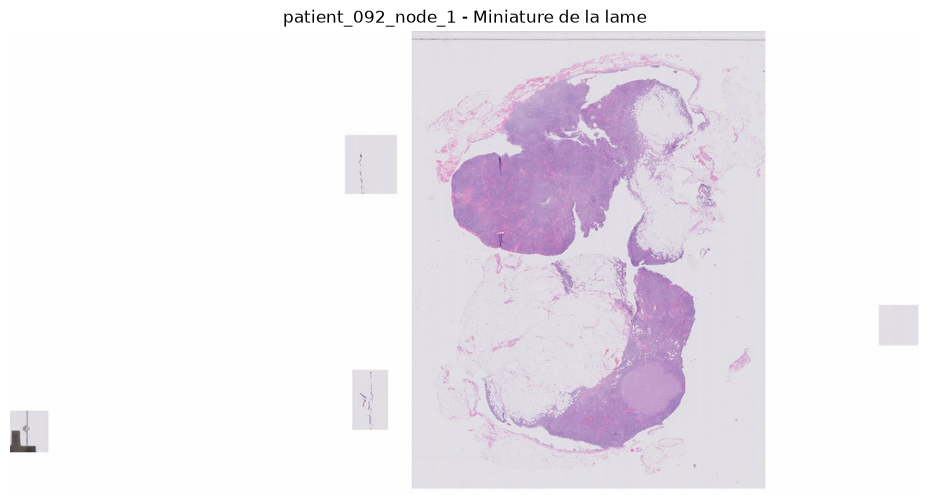

In [35]:
miniature_lame = lame.get_thumbnail((1000, 1000)) # Taille max (largeur/hauteur) en pixels
print("Taille de la miniature :", miniature_lame.size)

plt.figure(figsize=(12, 6))
plt.imshow(miniature_lame)
plt.axis("off")
plt.title("patient_092_node_1 - Miniature de la lame")
plt.show()

In [36]:
lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, "patient_092_node_1.tif"))
masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))

for nom, image in [("Lame", lame), ("Masque", masque)]:
    largeur, hauteur = image.level_dimensions[0]
    print(f"{nom} : niveau 0 = {largeur} x {hauteur} pixels, "
          f"{image.properties.get('openslide.mpp-x')} µm par pixel, "
          f"{image.level_count} niveaux")

Lame : niveau 0 = 184320 x 93696 pixels, 0.25 µm par pixel, 10 niveaux
Masque : niveau 0 = 184320 x 93696 pixels, 0.25 µm par pixel, 10 niveaux


> Les masques ont la même taille que les lames au niveau 0 avec la même taille de pixels. On pourra donc les utiliser plutôt que les annotations (cf la question restée posée à ce sujet en partie 5.1.1.) car la résolution est précise.

Taille de la miniature : (1000, 508)


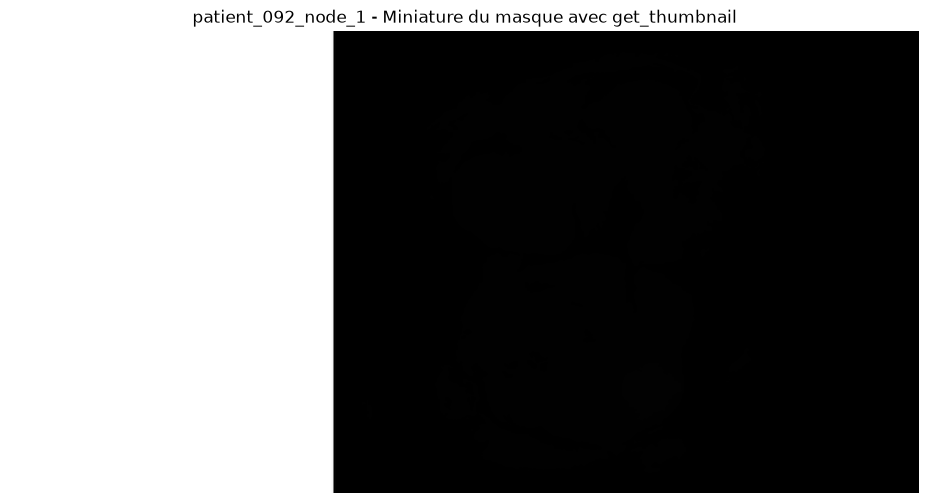

In [37]:
masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))
miniature_masque_get_thumbnail = masque.get_thumbnail((1000, 1000)) # Taille max (largeur/hauteur) en pixels
print("Taille de la miniature :", miniature_masque_get_thumbnail.size)

plt.figure(figsize=(12, 6))
plt.imshow(miniature_masque_get_thumbnail)
plt.axis("off")
plt.title("patient_092_node_1 - Miniature du masque avec get_thumbnail")
plt.show()

In [38]:
valeurs_miniature_masque = np.array(miniature_masque_get_thumbnail)
print(np.unique(valeurs_miniature_masque))

[  0   1   2   6 143 250 255]


On ne peut pas utiliser get_thumbnail tel quel pour les masques car :
- Pour une image classique, comme pour une lame ici, chaque pixel a trois valeurs (RGB, entre 0 et 255) correspondant aux trois canaux de l'image.
- Pour le masque, chaque pixel a ici une seule valeur : 0 (le fond), 1 (le tissu sain) ou 2 (la zone tumorale). Matplotlib affiche ici les valeurs sur une échelle de 0 à 255 donc 0, 1 et 2 apparaissent tous presque noirs. On pourrait le corriger en choisissant nos couleurs. Le problème est que get_thumbnail remplot les zones vides avec du blanc et fait la moyenne de pixels voisins donc on obtient des valeurs en dehors et 0, 1 et 2.

On va donc utiliser read_region qui ne fait pas ces "retouches" de get_thumbnail. On peut choisir un morceau de l'image si on le veut (get_thumbnail prend toute l'image), on choisit nous-même le niveau et on doit indiquer la taille exacte (pas la max).

In [39]:
niveau = 7
taille = masque.level_dimensions[niveau]

region_lame = lame.read_region((0, 0), niveau, taille)
region_masque = masque.read_region((0, 0), niveau, taille)

valeurs_lame = np.array(region_lame)
valeurs_masque = np.array(region_masque)[:, :, 0]

print("Taille lue au niveau", niveau, ":", taille)
print("Forme du tableau de la lame :", valeurs_lame.shape)
print("Forme du tableau du masque :", valeurs_masque.shape)
print("Valeurs présentes dans le masque :", np.unique(valeurs_masque))

Taille lue au niveau 7 : (1440, 732)
Forme du tableau de la lame : (732, 1440, 4)
Forme du tableau du masque : (732, 1440)
Valeurs présentes dans le masque : [0 1 2]


np.array transforme l’image en tableau de nombres (hauteur, largeur, canaux) avec 4 canaux pour RGB et la transparence A. Pour le masque on ne garde que le canal 0 qui contient 0, 1 ou 2.
OpenSlide donne la taille en largeur, hauteur d'où l'inversion.


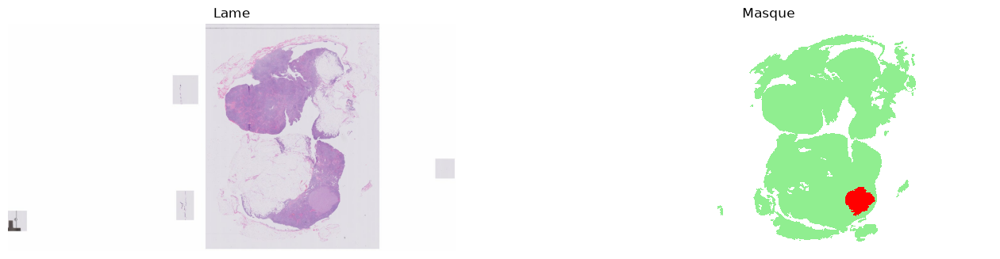

In [40]:
couleurs = ListedColormap(["white", "lightgreen", "red"]) # On liste les couleurs à utiliser pour 0, 1 et 2

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].imshow(valeurs_lame)
axes[0].set_title(f"Lame")
axes[0].axis("off")

axes[1].imshow(valeurs_masque, cmap=couleurs, vmin=0, vmax=2, interpolation="nearest")
axes[1].set_title("Masque")
axes[1].axis("off")

plt.show()

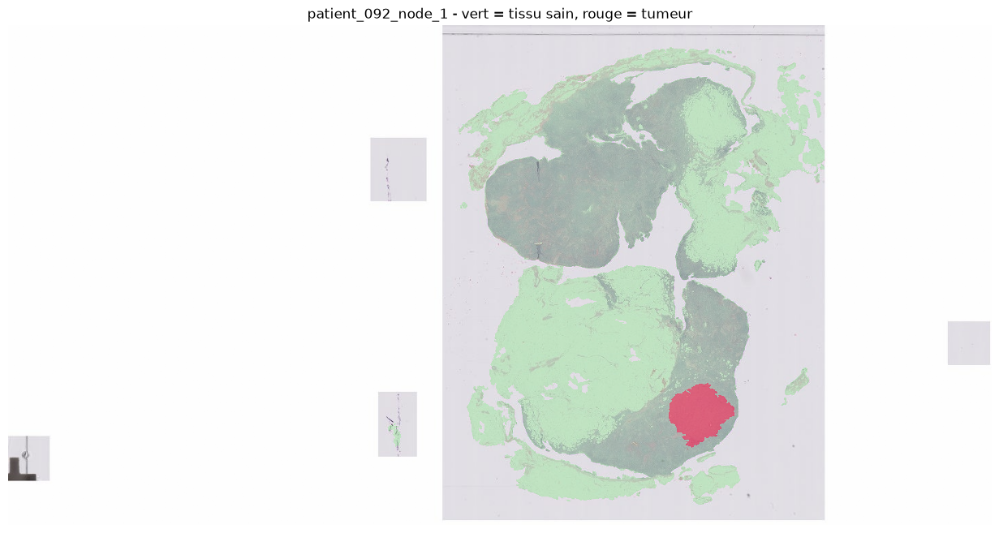

In [41]:
tissu_et_tumeur = np.ma.masked_where(valeurs_masque == 0, valeurs_masque) # On masque certains pixels 

plt.figure(figsize=(16, 8))
plt.imshow(valeurs_lame)
plt.imshow(tissu_et_tumeur, cmap=ListedColormap(["lightgreen", "red"]),
           vmin=1, vmax=2, alpha=0.4, interpolation="nearest")
plt.axis("off")
plt.title("patient_092_node_1 - vert = tissu sain, rouge = tumeur")
plt.show()

#### 5.1.3. Découper les lames en patchs

**Pourquoi faut-il découper les lames en patchs ?**

- L'image est beaucoup trop grande (pas possible avec les CNN)
- Si on réduisait l'image pour pouvoir utiliser un CNN, on perdrait le détail qui nous permet de voir les cellules tumorales
- Il y aurait trop peu d'exemples pour le modèle si on le faisait tourner sur les lames entières (une lame = une étiquette et l'étiquette ne dit pas où est la tumeur). C'est beaucoup plus précis avec les patchs.

**Les questions à se poser**

1. **Quelle surface choisir ? A quel niveau découper ? Quelle taille de patch choisir ?**
- Surface choisie : environ 100 à 200 µm soit assez pour voir un amas de cellules mais assez petit pour repérer les ITC
- Niveau 1 (0,5 µm par pixel) car une cellule tumorale y fait environ 20 pixels et c’est 4 fois moins coûteux que le niveau 0
- Taille de patch de 256 × 256 pixels (128 µm), proche des 224 pixels des modèles pré-entraînés

2. **Quel pas ?**
- 256 px, sans chevauchement, pour l’entraînement et la validation. 128 px avec 50 % de chevauchement pour analyser les lames entières.

3. **Comment repérer le tissu ?**
- Par les couleurs (saturation), pour toutes les lames. Le masque sert seulement aux étiquettes et à vérifier la détection.

4. **Combien de tissu minimum par patch ?**
- Au moins 25 %, mesuré sur le patch entier, avec la même règle pour tous les patchs.

5. **Comment étiqueter un patch ?**
- Tumoral s’il y a de la tumeur dans la zone centrale (128 × 128 px) et sain s’il n’y a aucune tumeur dans le patch, écarté sinon.

6. **Quel équilibre entre les classes ?**
- 50/50 : tous les patchs tumoraux, et autant de sains répartis entre les 3 lames d’entraînement.

7. **Comment enregistrer ?**
- Un tableau CSV et des PNG pour l’entraînement et la validation. Pour les lames entières, on lit les patchs à la volée et on enregistre seulement les prédictions.

> Cf Notion pour plus de précisions sur les décisions prises.

In [42]:
NIVEAU_PATCH = 1          # niveau de lecture des patchs (0,5 µm par pixel)
TAILLE_PATCH = 256        # côté du patch en pixels (128 µm)
PAS_ENTRAINEMENT = 256    # pas pour les patchs d'entraînement et de validation
TAILLE_CENTRE = 128       # largeur de la zone centrale pour l'étiquette
NIVEAU_TISSU = 5          # niveau réduit pour détecter le tissu
SEUIL_SATURATION = 0.04   # saturation minimale d'un pixel de tissu
SEUIL_TISSU = 0.25        # part minimale de tissu dans un patch
GRAINE = 42               # graine aléatoire pour les tirages (pour la reproductibilité)
QUOTA_TUMORAL = 1000      # nombre maximal de patchs tumoraux par lame (pour ne pas en avoir trop d'une même lame et limiter le nombre)

In [43]:
# Fonction pour lire une région en RGB

def lire_rgb(lame, position, niveau, taille):
    """Lit une région avec read_region et remplace les zones transparentes par du blanc."""
    region = lame.read_region(position, niveau, taille)
    image = Image.new("RGB", region.size, (255, 255, 255))
    image.paste(region, mask=region.split()[3])
    return image

# region.split() sépare l’image en ses canaux. On obtient 4 images à un seul canal (R, G, B, A).
# [3] prend la quatrième donc le canal A. C’est une image où chaque pixel vaut 255 ou 0 (si transparent).
# image.paste(region, mask=...) colle region sur l’image blanche et le paramètre mask dit, pixel par pixel, si on colle ou non : si A vaut 0 = False, on ne colle rien et le blanc reste.

read_region renvoie une image RGBA et on a besoin de la convertir en RGB pour le modèle (c'est ce qu'il attend). Or, si on la convertit directement en RGB, les zones transparentes (donc non numérisées) deviennent noires car un pixel vide = (0,0,0,0) et donc en RGA (0,0,0). 
Cette fonction crée une image blanche puis colle la région par-dessus. Ainsi, les zones transparentes restent blanches.

In [44]:
# Fonction qui détecte le tissu en fonction de la couleur (saturation)

def masque_tissu(lame, niveau=NIVEAU_TISSU, seuil=SEUIL_SATURATION):
    """Renvoie un tableau de booléens : True là où il y a du tissu (saturation au-dessus du seuil)."""
    region = np.array(lame.read_region((0, 0), niveau, lame.level_dimensions[niveau])) # On obtient un tableau Numpy à 3 dimensions rempli de nombres entre 0 et 255 (on en a besoin pour faire des calculs sur les pixels, ici ceux transparents par ex)
    rgb = region[:, :, :3].copy() # region[:, :, :3] garde R, G et B
    rgb[region[:, :, 3] == 0] = 255 # On met en blanc les pixels transparents (region[:, :, 3] == 0 -> on met 255 dans les trois canaux pour tous ces pixels)
    hsv = np.array(Image.fromarray(rgb).convert("HSV")) # Image.fromarray(rgb).convert("HSV") convertit en HSV qui nous permet d'avoir la saturation
    saturation = hsv[:, :, 1] / 255 # Le canal 1 est la saturation entre 0 et 255 qu’on divise par 255 pour l’avoir entre 0 et 1 qui est l'échelle de la saturation
    return saturation > seuil # saturation > seuil donne un tableau de True/False qui correspond à notre masque de tissu

On lit toute la lame au niveau 5 pour que ce soit plus rapide qu'à un niveau inférieur et c'est suffisant pour détecter le tissu.

Part de la lame détectée comme tissu (couleurs) : 0.141
Part de la lame en tissu selon le masque officiel : 0.203
Part du tissu officiel retrouvée par notre détection : 0.68
Part de notre tissu qui est aussi du tissu officiel : 0.978


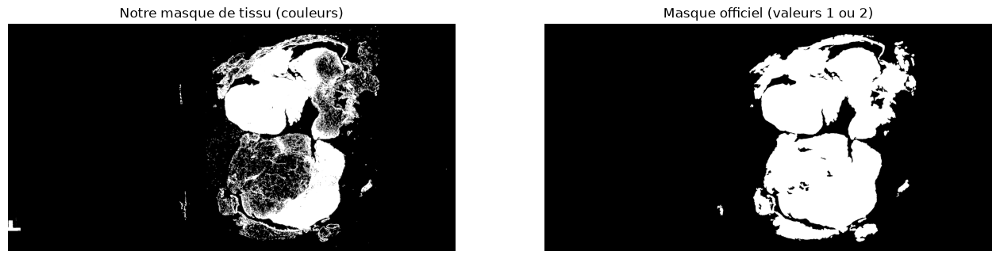

In [45]:
# Comparaison de notre détection du tissu au masque officiel

masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))
masque_reduit = np.array(masque.read_region((0, 0), NIVEAU_TISSU, masque.level_dimensions[NIVEAU_TISSU]))[:, :, 0] # On garde le canal 0 qui contient 0, 1 ou 2

tissu = masque_tissu(lame) # Renvoie un tableau de True (pour le tissu) /False (pour le fond)
tissu_officiel = masque_reduit > 0 # Idem

print("Part de la lame détectée comme tissu (couleurs) :", round(tissu.mean(), 3))
print("Part de la lame en tissu selon le masque officiel :", round(tissu_officiel.mean(), 3))
print("Part du tissu officiel retrouvée par notre détection :", round((tissu & tissu_officiel).sum() / tissu_officiel.sum(), 3))
print("Part de notre tissu qui est aussi du tissu officiel :", round((tissu & tissu_officiel).sum() / tissu.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(tissu, cmap="gray")
axes[0].set_title("Notre masque de tissu (couleurs)")
axes[0].axis("off")
axes[1].imshow(tissu_officiel, cmap="gray")
axes[1].set_title("Masque officiel (valeurs 1 ou 2)")
axes[1].axis("off")
plt.show()


Résultats sur la lame 092 : 
- 98 % de ce qu’on détecte est bien du tissu (presque aucune fausse détection) et on retrouve 68 % du tissu officiel. 
- Ce qu’on manque ce sont surtout des zones très pâles que le masque officiel compte comme tissu mais ce n’est pas gênant car aucun patch tumoral n’est perdu (voir plus bas).
- Par contre on voit ici qu'on a pris un petit bout en bas à gauche alors que ce n'est pas du tissu. Ca ajoute quelques faux patchs sains.

In [46]:
# Fonction qui liste les patchs et les étiquettes
# Elle parcourt l'image patch par patch
# Si patch sans tissu : exclu
# Si patch avec tissu, elle regarde si s'il y a de la tumeur ou non pour l'étiqueter
# Elle écarte les patchs avec .........

def lister_patchs(nom_lame, nom_set, pas=PAS_ENTRAINEMENT):
    """Parcourt la lame sur une grille et renvoie un tableau des patchs qui contiennent du tissu."""
    lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
    masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, nom_lame + "_mask.tif"))
    tissu = masque_tissu(lame)

    facteur_patch = int(lame.level_downsamples[NIVEAU_PATCH]) # Permet de savoir de combien on réduit par rapport au niveau 0 car read_me attend ses positions dans le repère du niveau 0
    facteur_tissu = int(lame.level_downsamples[NIVEAU_TISSU]) # Idem
    taille_0 = TAILLE_PATCH * facteur_patch      # Combien fait de côté le patch, en pixels du niveau 0 !
    pas_0 = pas * facteur_patch                  # Idem pour le pas : en pixels du niveau 0
    debut_centre = (TAILLE_PATCH - TAILLE_CENTRE) // 2 # A quelle position commence le centre qu'on a définit
    fin_centre = debut_centre + TAILLE_CENTRE # La fin du centre
    largeur_0, hauteur_0 = lame.dimensions # Dimensions de la lame

    patchs = [] # Contiendra une ligne par patch
    for y in range(0, hauteur_0 - taille_0 + 1, pas_0): # On parcourt chaque "ligne" de 512 px de hauteur. A noter : si patch incomplet en fin de ligne, il est écarté
        for x in range(0, largeur_0 - taille_0 + 1, pas_0): # Et pour chaque ligne, chaque colone de 512 px de largeur
            zone_tissu = tissu[y // facteur_tissu:(y + taille_0) // facteur_tissu,
                               x // facteur_tissu:(x + taille_0) // facteur_tissu]
            # Le patch, lui est repéré en coordonnées du niveau 0 : il va de x à x + 512 en largeur et de y à y + 512 en hauteur.
            # Pour trouver le même carré dans tissu, on divise ses 4 bords par 32
            # zone_tissu est donc un petit tableau de 16 × 16 cases (512/32) True/False qui se trouvent sous le patch.            
            pct_tissu = zone_tissu.mean() # On calcule la part de tissu dans le carré
            if pct_tissu == 0:
                continue

            zone_masque = np.array(masque.read_region((x, y), NIVEAU_PATCH, (TAILLE_PATCH, TAILLE_PATCH)))[:, :, 0] # On regarde dans la masque "officiel" dans le canal 0 qui contient 0, 1 ou 2
            pct_tumeur = (zone_masque == 2).mean()
            pct_tumeur_centre = (zone_masque[debut_centre:fin_centre, debut_centre:fin_centre] == 2).mean()

            if pct_tumeur_centre > 0:
                etiquette = "tumoral"
            elif pct_tumeur == 0:
                etiquette = "sain"
            else:
                etiquette = "ecarte"
            # On garde les patchs sans tumeur dans tout le patch, ceux avec tumeur au centre mais on écartera ceux avec tumeur juste au bord car cas ambigu pour l'entrainement

            patchs.append({
                "lame": nom_lame, "set": nom_set, "x": x, "y": y, "niveau": NIVEAU_PATCH,
                "pct_tissu": round(pct_tissu, 3), "pct_tumeur": round(pct_tumeur, 4),
                "pct_tumeur_centre": round(pct_tumeur_centre, 4),
                "assez_de_tissu": pct_tissu >= SEUIL_TISSU, "etiquette": etiquette,
            })
    return pd.DataFrame(patchs)

In [47]:
# On applique aux lames d’entraînement et de validation

selection = pd.read_csv("../data/prototype/selection_lames_prototype.csv")
lames_patchs = selection[selection["set"].isin(["entrainement", "validation"])] # On applique qu'aux lames de validation et entrainement

tableaux = [] # On obtiendra une liste de dataframes (un df par lame)
for _, ligne in lames_patchs.iterrows():
    debut = time.time() # L'heure au début du traitement
    tableau = lister_patchs(ligne["lame"], ligne["set"]) # Le dataframe d'une lame
    tableaux.append(tableau) 
    print(f"{ligne['lame']} : {len(tableau)} patchs avec du tissu ({time.time() - debut:.0f} s)")

candidats = pd.concat(tableaux, ignore_index=True) # Empile les dataframes

patient_089_node_3 : 7577 patchs avec du tissu (13 s)
patient_096_node_0 : 16493 patchs avec du tissu (29 s)
patient_083_node_4 : 2994 patchs avec du tissu (5 s)
patient_092_node_1 : 13872 patchs avec du tissu (21 s)


In [48]:
# On regarde les patchs obtenus, par lame et catégorie (a écarter, sain, tumoral)

peu_de_tissu = ~candidats["assez_de_tissu"]
ambigu = candidats["etiquette"] == "ecarte"
ecartes = candidats[peu_de_tissu | ambigu].copy()
utilisables = candidats[~peu_de_tissu & ~ambigu]

ecartes["raison"] = "ambigu"
ecartes.loc[~ecartes["assez_de_tissu"], "raison"] = "peu de tissu"

print("Patchs utilisables :")
display(pd.crosstab([utilisables["set"], utilisables["lame"]], utilisables["etiquette"], margins=True))

print("Patchs écartés :")
display(pd.crosstab([ecartes["set"], ecartes["lame"]], ecartes["raison"], margins=True))

perdus = ecartes[(ecartes["raison"] == "peu de tissu") & (ecartes["etiquette"] == "tumoral")]
print("Patchs tumoraux écartés par le seuil de tissu :", len(perdus))

Patchs utilisables :


etiquette                         sain  tumoral    All
set          lame                                     
entrainement patient_083_node_4   2859        0   2859
             patient_089_node_3   6603        7   6610
             patient_096_node_0   7455     7725  15180
validation   patient_092_node_1  10942      388  11330
All                              27859     8120  35979

Patchs écartés :


raison                           ambigu  peu de tissu   All
set          lame                                          
entrainement patient_083_node_4       0           135   135
             patient_089_node_3       6           961   967
             patient_096_node_0     190          1123  1313
validation   patient_092_node_1      29          2513  2542
All                                 225          4732  4957

Patchs tumoraux écartés par le seuil de tissu : 0


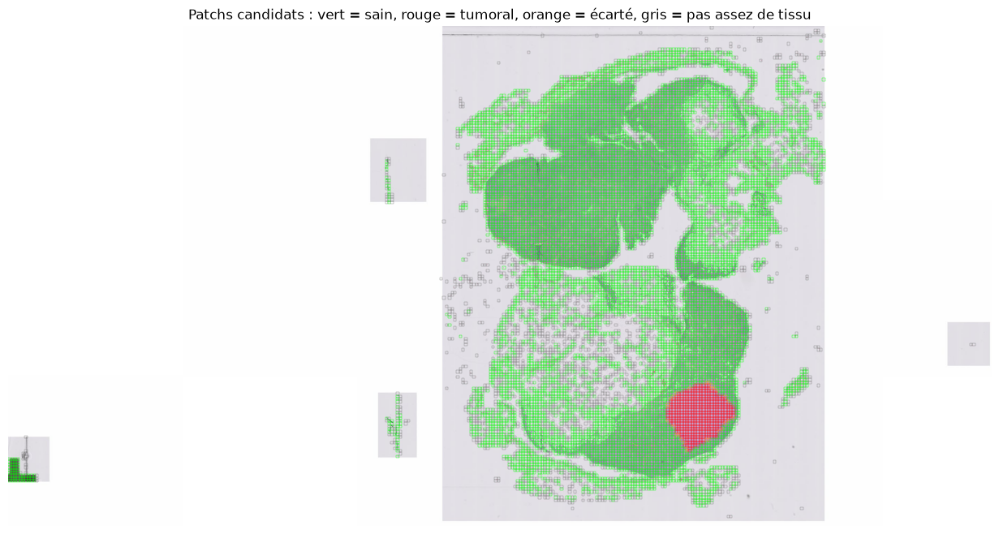

In [49]:
# Voir les patchs sur la lame pour vérifier (ex avec patient_092_node_1)

nom_lame = "patient_092_node_1"
lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
niveau_vue = 6 # Juste pour l'affichage ici donc niveau élevé
vue = lire_rgb(lame, (0, 0), niveau_vue, lame.level_dimensions[niveau_vue])
facteur_vue = lame.level_downsamples[niveau_vue] # Donne le facteur pour la vue de niveau 6
taille_vue = TAILLE_PATCH * lame.level_downsamples[NIVEAU_PATCH] / facteur_vue # Patch au niveau 1 vs vue au niveau 6 donc on réduit la taille du ptach (en passant par le niveau 0)
couleurs = {"sain": "lime", "tumoral": "red", "ecarte": "orange"}

fig, ax = plt.subplots(figsize=(16, 8))
ax.imshow(vue)
for _, p in candidats[candidats["lame"] == nom_lame].iterrows():
    couleur = couleurs[p["etiquette"]] if p["assez_de_tissu"] else "gray"
    ax.add_patch(Rectangle((p["x"] / facteur_vue, p["y"] / facteur_vue), taille_vue, taille_vue,
                           fill=False, edgecolor=couleur, linewidth=0.3))
ax.set_title("Patchs candidats : vert = sain, rouge = tumoral, orange = écarté, gris = pas assez de tissu")
ax.axis("off")
plt.show()

In [50]:
# Choix final des patchs

morceaux = [] # Contiendra les patchs choisis sous forme d'un df par paquet choisi
for nom_set in ["entrainement", "validation"]:
    patchs_set = utilisables[utilisables["set"] == nom_set]
    lames_set = patchs_set["lame"].unique()

    # On prend tous les patchs tumoraux dans la limite définie par lame (1000)
    nb_tumoraux = 0
    for nom_lame in lames_set:
        tumoraux_lame = patchs_set[(patchs_set["lame"] == nom_lame) & (patchs_set["etiquette"] == "tumoral")] # On prend tous les patchs tumoraux de la lame
        choisis = tumoraux_lame.sample(n=min(len(tumoraux_lame), QUOTA_TUMORAL), random_state=GRAINE) # On en tire au hasard 1000 s'il y en a plus
        morceaux.append(choisis) # On les ajoute à la liste morceaux
        nb_tumoraux += len(choisis)

    # On prend des patchs sains répartis à parts égales entre les lames dans la même proportion que les tumoraux
    nb_sains_par_lame = nb_tumoraux // len(lames_set)
    for nom_lame in lames_set:
        sains_lame = patchs_set[(patchs_set["lame"] == nom_lame) & (patchs_set["etiquette"] == "sain")]
        choisis = sains_lame.sample(n=min(len(sains_lame), nb_sains_par_lame), random_state=GRAINE)
        morceaux.append(choisis)

echantillon = pd.concat(morceaux, ignore_index=True) # On empile dans un seul df

display(pd.crosstab([echantillon["set"], echantillon["lame"]], echantillon["etiquette"], margins=True))

etiquette                        sain  tumoral   All
set          lame                                   
entrainement patient_083_node_4   335        0   335
             patient_089_node_3   335        7   342
             patient_096_node_0   335     1000  1335
validation   patient_092_node_1   388      388   776
All                              1393     1395  2788

In [51]:
# Enregistrement des patchs

os.makedirs("../data/prototype/patchs", exist_ok=True)
DOSSIER_PATCHS = "../data/prototype/patchs"

debut = time.time()
for nom_lame in echantillon["lame"].unique():
    lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
    patchs_lame = echantillon[echantillon["lame"] == nom_lame]
    for index, p in patchs_lame.iterrows(): # On parcourt les patchs
        dossier = os.path.join(DOSSIER_PATCHS, p["set"], p["etiquette"]) # On construit le dossier de destination pour l'enregistrement
        os.makedirs(dossier, exist_ok=True) #On crée le dossier si non existant
        nom_fichier = f"{nom_lame}_x{p['x']}_y{p['y']}.png" # Nom du fichier construit sur la base de la lame et la position du patch
        image = lire_rgb(lame, (int(p["x"]), int(p["y"])), NIVEAU_PATCH, (TAILLE_PATCH, TAILLE_PATCH)) # On découpe le patch
        image.save(os.path.join(dossier, nom_fichier)) # On l'enregistre
        echantillon.loc[index, "fichier"] = os.path.join(p["set"], p["etiquette"], nom_fichier) # On note dans le df, sur la ligne du patch, où l'image est enregistrée
    print(f"{nom_lame} : {len(patchs_lame)} patchs enregistrés")

echantillon.to_csv(os.path.join(DOSSIER_PATCHS, "patchs.csv"), index=False) # On enregistre l tableau en csv

print(f"Terminé en {time.time() - debut:.0f} s")

patient_089_node_3 : 342 patchs enregistrés
patient_096_node_0 : 1335 patchs enregistrés
patient_083_node_4 : 335 patchs enregistrés
patient_092_node_1 : 776 patchs enregistrés
Terminé en 28 s


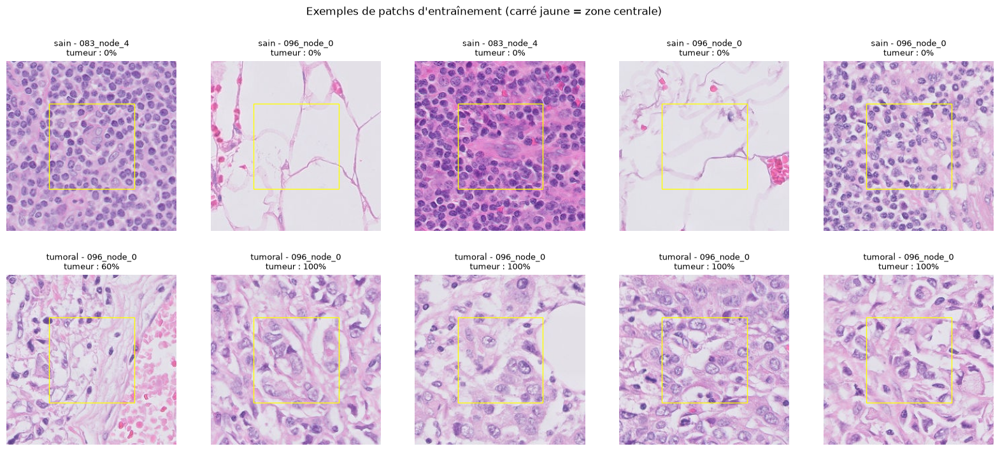

In [52]:
# Vérification visuelle des patchs (à partir de quelques exemples)

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
debut_centre = (TAILLE_PATCH - TAILLE_CENTRE) // 2
for i, etiquette in enumerate(["sain", "tumoral"]):
    exemples = echantillon[(echantillon["set"] == "entrainement") & (echantillon["etiquette"] == etiquette)].sample(n=5, random_state=GRAINE)
    for j, (_, p) in enumerate(exemples.iterrows()):
        image = Image.open(os.path.join(DOSSIER_PATCHS, p["fichier"]))
        axes[i, j].imshow(image)
        axes[i, j].add_patch(Rectangle((debut_centre, debut_centre), TAILLE_CENTRE, TAILLE_CENTRE,
                                       fill=False, edgecolor="yellow", linewidth=1))
        axes[i, j].set_title(f"{etiquette} - {p['lame'][8:]}\ntumeur : {p['pct_tumeur']:.0%}", fontsize=9)
        axes[i, j].axis("off")
plt.suptitle("Exemples de patchs d'entraînement (carré jaune = zone centrale)")
plt.show()

#### 5.1.4. Entrainement du modèle de patchs

In [53]:
appareil = "xpu" if torch.xpu.is_available() else "cpu"
print("Calculs sur :", appareil)

patchs = pd.read_csv(os.path.join(DOSSIER_PATCHS, "patchs.csv"))
print(patchs.groupby(["set", "etiquette"]).size())

Calculs sur : xpu
set           etiquette
entrainement  sain         1005
              tumoral      1007
validation    sain          388
              tumoral       388
dtype: int64


In [55]:
preparation = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

On définit ici les étapes qu'on appliquera sur chaque patch :
- .ToTensor() pour transformer l'image en tenseur PyTorch en faisant deux changements :
    - L'ordre des dimensions : (hauteur, largeur, canaux) poru les images et PyTorch veut (canaux, hauteur, largeur)
    - Les valeurs passent de 0-255 à 0-1 (les réseaux fonctionnent mieux avec des petites valeurs)
- .Normalize()  pour normaliser les valeurs sur chaque canal : (valeur - moyenne du canal) / écart-type du canal calculé sur les photos d'ImageNet, base de ResNet18. On obtient des valeurs centrées autour de 0. On utilise les valeurs utilisées pour ResNet18 pour appliquer exactement la même normalisation. On a ainsi des valeurs centrées autour de 0 et étalées de la même façon pour chaque canal. Cela rend l'apprentissage par descente de gradient est plus stable et plus rapide. Et surtout, encore une fois, on a ainsi la même chose que cequ'avait le modèle pour son entrainement et ses filtres reçoivent ainsi des nombres ressemblants à ceux pour lesquels ils ont été réglés.

In [56]:
class PatchsDataset(Dataset): # On hérite de la classe Dataset PyTorch
    """Lit les patchs PNG listés dans un tableau et renvoie (image préparée, étiquette)."""

    def __init__(self, tableau, dossier, transformation): # Appelée quand on crée l'objet
        self.tableau = tableau.reset_index(drop=True)
        self.dossier = dossier
        self.transformation = transformation

    def __len__(self):
        return len(self.tableau)

    def __getitem__(self, i):
        ligne = self.tableau.iloc[i]
        image = Image.open(os.path.join(self.dossier, ligne["fichier"])).convert("RGB")
        etiquette = 1 if ligne["etiquette"] == "tumoral" else 0
        return self.transformation(image), etiquette

On crée ici une classe, un Dataset qui est un programme qui explique comment lire des données dans PyTorch.
PyTorch ne sait pas comment les données sont rangées donc il a besoin qu'on lui remplisse un genre de formulaire qui correspond à cette classe Dataset. Il abesoin de réponses à deux questions :
- Combien de données y a-t-il ?
- Comment obtient-on la donnée numéro i ?

On écrit ici notre Dataset en répondant à ces deux questions avec __len__ et __getitem__.

En pratique on fera :
jeu_entrainement = PatchsDataset(patchs_entrainement, DOSSIER_PATCHS, preparation)  # Ca appellera __init__
len(jeu_entrainement)             # Ca appellera __len__
image, etiquette = jeu_entrainement[0]   # Ca appellera __getitem__(0) qui renverra l'image sous forme de tenseur après application des étapes de pparation et l'étiquette 1

In [58]:
patchs_entrainement = patchs[patchs["set"] == "entrainement"]
patchs_validation = patchs[patchs["set"] == "validation"]

jeu_entrainement = PatchsDataset(patchs_entrainement, DOSSIER_PATCHS, preparation)
jeu_validation = PatchsDataset(patchs_validation, DOSSIER_PATCHS, preparation)

chargeur_entrainement = DataLoader(jeu_entrainement, batch_size=64, shuffle=False, num_workers=0)
chargeur_validation = DataLoader(jeu_validation, batch_size=64, shuffle=False, num_workers=0)

images, etiquettes = next(iter(chargeur_entrainement)) # Récupère le premier lot du jeu d'entrainement (le tenseur (64, 3, 256, 256) = les images et le tenseur (64,) avec des 0 et 1 = les étiquettes)
print("Nombre de patchs :", len(jeu_entrainement), "en entraînement,", len(jeu_validation), "en validation")
print("Forme d'un lot d'images :", images.shape)
print("Forme d'un lot d'étiquettes :", etiquettes.shape)
print("Valeurs : min", round(images.min().item(), 2), "max", round(images.max().item(), 2)) # Pour vérifier que la normalisation a marché

Nombre de patchs : 2012 en entraînement, 776 en validation
Forme d'un lot d'images : torch.Size([64, 3, 256, 256])
Forme d'un lot d'étiquettes : torch.Size([64])
Valeurs : min -1.41 max 2.64


jeu_entrainement c'est un objet qui donne un patch à la fois quand on lui demande son numéro. Il ne contient pas les images mais le tableau de tous les patchs d’entraînement et sait aller chercher chacun.
image, etiquette = jeu_entrainement[0] renverra le tenseur et l'étiquette pour le patch 0

chargeur_entrainement c'est un DataLoader c'est à dire un objet qui donne les patchs par lots (ici 64). Il demande lui-même les patchs au Dataset (0, 1, 2, … 63), les empile et renvoie le lot. Puis il recommence avec 64 à 127, et ainsi de suite.
On travaille par lot car un par un serait lent et tout d'un coup serait trop lourd. Ces lots sont envoyés un par un au réseau qui reçoit donc un tenseur de forme (64, 3, 256, 256). Ce tenseur traverse le réseau d’un bloc et chaque couche applique ses calculs aux 64 images à la fois : la première couche de convolution passe ses filtres sur les 64 images en même temps, puis la deuxième couche reçoit les 64 résultats, et ainsi de suite.
À la sortie, on obtient un tenseur de forme (64, 512) : les 512 caractéristiques de chacune des 64 images, en un seul passage.
Puis on recommence avec le lot suivant, et ainsi de suite jusqu’au dernier.

- Entrée : tenseur (64, 3, 256, 256) = (nombre d'images, nombre de canaux, hauteur, largeur).
- Sortie de la première couche de convolution + max pooling : tenseur (64, 64, 64, 64) = (64 images, 64 canaux correspondant aux 64 filtres définis par ResNet18 pour la première couche, hauteur initiale / 4, largeur initiale / 4, réduction prévue par ResNet18).
- Sortie du bloc 1 (4 convolutions) : tenseur (64, 64, 64, 64) : même taille, même nombre de canaux.
- Sortie du bloc 2 (4 convolutions) : tenseur (64, 128, 32, 32) : taille / 2, canaux × 2.
- Sortie du bloc 3 (4 convolutions) : tenseur (64, 256, 16, 16) : taille / 2, canaux × 2.
- Sortie du bloc 4 (4 convolutions) : tenseur (64, 512, 8, 8) : taille / 2, canaux × 2.
- Moyenne de chaque carte de 8 × 8 : tenseur (64, 512) : 512 caractéristiques par image.

In [62]:
# Chargement de ResNet18

modele = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1) # Cela crée un ResNet18 et y charge les poids appris sur ImageNet (à faire absolument sinon on a pas les poids donc des poids aléatoires et un ResNet18 qui ne saurait rien)
modele.fc = torch.nn.Identity() # Pour retirer la dernière couche fc et la remplacer par Identity
modele = modele.to(appareil) # Envoie le modèle (tous ses poids) sur ma carte Intel
modele.eval() # On met le modèle en mode évaluation et non entrainement (dans notre cas on cherche à prédire, pas à entraîner le modèle)

print("Dernière couche :", modele.fc)

Dernière couche : Identity()


On remplace la dernière couche fc par Identity qui renvoie le résultat de la couche précédente car :
- ResNet18 a été entraîné sur ImageNet pour répondre à la question « cette photo montre-t-elle un chien, un chat, une voiture, une tasse… ? », parmi 1 000 catégories. Sa dernière couche transforme les 512 caractéristiques en 1 000 scores, un par catégorie.
- Nous on veut les 512 caractéristiques qui arrivent dans cette dernière couche et qui sont un résumé visuel du patch : quelles textures, quelles formes, quels contrastes, quels motifs sont présents. En apprenant à reconnaître 1 000 catégories d’objets, le réseau a dû apprendre à décrire n’importe quelle image de façon riche. Cette description est utile pour d’autres tâches que celles d’ImageNet, y compris la nôtre : un patch tumoral (grandes cellules pâles, noyaux clairs) n’a pas le même « résumé » qu’un patch sain (petits noyaux sombres et serrés).

In [ ]:
# Fonction pour extraire les caractéristique

def extraire_caracteristiques(chargeur):
    """Fait passer tous les lots d'un chargeur dans ResNet18 et renvoie les caractéristiques et les étiquettes."""
    toutes_caracteristiques = []
    toutes_etiquettes = []
    with torch.no_grad(): # Pour dire à PyTorch de ne pas enregistrer les calculs pour l’apprentissage (les gradients) car on entraîne pas le modèle nous
        for images, etiquettes in chargeur:
            images = images.to(appareil)
            caracteristiques = modele(images)
            toutes_caracteristiques.append(caracteristiques.cpu().numpy()) # .cpu().numpy() ramène le résultat de la carte vers la mémoire normale (.cpu()), puis le transforme en tableau NumPy (.numpy()) et on l'ajoute à la liste qui est donc une liste de tableaux avec un tableau par lot
            toutes_etiquettes.append(etiquettes.numpy())
    return np.concatenate(toutes_caracteristiques), np.concatenate(toutes_etiquettes) # On empile les tableaux de tous les lots en un seul

Cette fonction fait passer chaque patch dans ResNet18 et récupère les 512 caractéristiques qui sortent à la fin.

A la fin on obtient un tableau avec une ligne par patch et une colonne par caractéristique (512) et un autre tableau avec une ligne par patch et une colonne d'étiquette.

In [68]:
DOSSIER_RESULTATS = "../data/prototype/resultats/strategie_1"
os.makedirs(DOSSIER_RESULTATS, exist_ok=True)

debut = time.time()
X_entrainement, y_entrainement = extraire_caracteristiques(chargeur_entrainement)
X_validation, y_validation = extraire_caracteristiques(chargeur_validation)
print(f"Caractéristiques calculées en {time.time() - debut:.0f} s")
print("Entraînement :", X_entrainement.shape, "- validation :", X_validation.shape)

np.save(os.path.join(DOSSIER_RESULTATS, "X_entrainement.npy"), X_entrainement)
np.save(os.path.join(DOSSIER_RESULTATS, "y_entrainement.npy"), y_entrainement)
np.save(os.path.join(DOSSIER_RESULTATS, "X_validation.npy"), X_validation)
np.save(os.path.join(DOSSIER_RESULTATS, "y_validation.npy"), y_validation)

Caractéristiques calculées en 31 s
Entraînement : (2012, 512) - validation : (776, 512)


On a maintenant pour le jeu d'entraînement et pour le jeu de validation :
- X : les 512 caractéristiques extraites par ResNet18 pour chaque patch
- y : l'étiquette de chaque patch (0 si sain, 1 si tumoral)

On entraîne ensuite une régression logistique sur ces caractéristiques (standardisées dans un pipeline, pour que la standardisation soit apprise sur l'entraînement seulement).

On fait de l'hyperparameter tuning pour deux hyperparamètres :
- C (la force de la régularisation) : on teste avec 0,001 / 0,01 / 0,1 / 1 / 10
- Le type de régularisation : L2 ou L1 (l1_ratio = 0 ou 1)
Cela fait 10 combinaisons, chacune entraînée sur l'entraînement et évaluée sur la validation. On gardera celle qui donnera la meilleure AUC.

On utilise une validation simple pour le prototype (la lame 092) plutôt qu'une validation croisée car trop peu de lames mais pour la solution finale on fera une validation croisée par patiente.

On choisira le seuil de décision en privilégiant le rappel (par exemple le seuil qui donne au moins 95 % de rappel), puis on regardera la matrice de confusion, l'exactitude, le rappel et la précision.

In [64]:
# Entrainement du modèle avec hyperparameter tuning, validation croisée et comparaison des performances sur AUC

resultats = []
for regularisation, l1_ratio in [("L2", 0), ("L1", 1)]:
    for C in [0.001, 0.01, 0.1, 1, 10]:
        classifieur = make_pipeline(StandardScaler(), # On standardise parce qu'on applique une régularisation (qui va pénaliser les grands coefficients or une variable à petite échelle qui a de l'importance aura un plus grand coefficient)
                                    LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=5000))
        # On crée un modèle avec ses étapes en utilisant un pipeline
        # On utilise make_pipeline, une fonction de scikit-learn. Les étapes s’enchaînent sur les données qu’on lui donnera plus tard : chaque étape transforme X et passe le résultat à l’étape suivante
        # Dans un pipeline de scikit-learn, les transformations ne s'appliquent qu'à X
        classifieur.fit(X_entrainement, y_entrainement) # Entrainement du modèle
        proba_validation = classifieur.predict_proba(X_validation)[:, 1] # On applique notre modèle au set de validation et on récupère la probabilité d'être de la classe 1 (tumoral)
        auc = roc_auc_score(y_validation, proba_validation) # On calcule l'AUC
        resultats.append({"régularisation": regularisation, "l1_ratio": l1_ratio, "C": C, "AUC validation": round(auc, 4)}) # On ajoute le résultat pour ce modèle (après ses hyperparamètres) dans la liste de résultat

tableau_resultats = pd.DataFrame(resultats).sort_values("AUC validation", ascending=False) # On transforme en df
display(tableau_resultats)

c:\Users\joell\projets\projet-camelyon17\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,régularisation,l1_ratio,C,AUC validation
0,L2,0,0.001,0.9847
1,L2,0,0.010,0.9793
7,L1,1,0.100,0.9736
2,L2,0,0.100,0.9641
8,L1,1,1.000,0.9591
6,L1,1,0.010,0.9542
9,L1,1,10.000,0.9535
3,L2,0,1.000,0.9487
4,L2,0,10.000,0.9445
5,L1,1,0.001,0.5000


In [ ]:
# Modèle final retenu

meilleur = tableau_resultats.iloc[0] # Modèle avec le meilleur AUC
print("Retenu :", meilleur["régularisation"], "avec C =", meilleur["C"]) # Affichage des hyperparamètres retenus, ceux du meilleur modèle en terme de performance AUC sur la validation

classifieur = make_pipeline(StandardScaler(),
                            LogisticRegression(C=meilleur["C"], l1_ratio=meilleur["l1_ratio"], solver="saga", max_iter=5000))
classifieur.fit(X_entrainement, y_entrainement)
proba_validation = classifieur.predict_proba(X_validation)[:, 1]
print("AUC sur la validation :", round(roc_auc_score(y_validation, proba_validation), 4))

Retenu : L2 avec C = 0.001
AUC sur la validation : 0.9847


Rappel sur l'AUC :
Si je prends au hasard un patch vraiment tumoral et un patch vraiment sain, quelle est la probabilité que le modèle donne une probabilité plus haute au tumoral ?
- AUC = 1 : le modèle classe toujours les tumoraux au-dessus des sains. Il existe un seuil qui les sépare parfaitement.
- AUC = 0,5 : il fait comme le hasard.
> Notre 0,9847 : dans 98,5 % des paires (un tumoral, un sain), le tumoral a la probabilité la plus haute.

In [ ]:
# Recherche du meilleur seuil : choix d'optimiser le rappel (95%) 

def afficher_metriques(y_vrai, proba, seuil):
    """Affiche la matrice de confusion, l'exactitude, le rappel et la précision pour un seuil donné."""
    y_predit = (proba >= seuil).astype(int)
    vn, fp, fn, vp = confusion_matrix(y_vrai, y_predit).ravel()
    print(f"Seuil : {seuil:.3f}")
    print(f"  Matrice de confusion : VP = {vp}, FN = {fn}, FP = {fp}, VN = {vn}")
    print(f"  Exactitude : {accuracy_score(y_vrai, y_predit):.3f}")
    print(f"  Rappel     : {recall_score(y_vrai, y_predit):.3f}")
    print(f"  Précision  : {precision_score(y_vrai, y_predit):.3f}")

afficher_metriques(y_validation, proba_validation, 0.5)

taux_fp, taux_vp, seuils = roc_curve(y_validation, proba_validation) # roc_curve essaie chaque seuil possible du plus haut au plus bas et calcule pour chacun le rappel (taux_vp, le taux de vrais positifs) et le taux de fausses alertes (taux_fp, la part des sains classés tumoraux).
seuil_rappel_95 = seuils[np.argmax(taux_vp >= 0.95)] # On prend le premier seuil (le plus haut) qui permet d'avoir un rappel d'au moins 95%
afficher_metriques(y_validation, proba_validation, seuil_rappel_95)

Seuil : 0.500
  Matrice de confusion : VP = 194, FN = 194, FP = 3, VN = 385
  Exactitude : 0.746
  Rappel     : 0.500
  Précision  : 0.985
Seuil : 0.218
  Matrice de confusion : VP = 370, FN = 18, FP = 12, VN = 376
  Exactitude : 0.961
  Rappel     : 0.954
  Précision  : 0.969


Pour rappel :
- Exactitude : sur tous les patchs, quelle part est bien classée ? (VP + VN) / total.
- Rappel : sur les patchs vraiment tumoraux, quelle part a-t-on trouvée ? VP / (VP + FN). Il mesure les tumeurs manquées : un rappel de 0,95 veut dire qu’on en manque 5 %.
- Précision : sur les patchs qu’on a dits tumoraux, quelle part l’est vraiment ? VP / (VP + FP). Elle mesure les fausses alertes : une précision de 0,90 veut dire que 10 % de nos alertes sont fausses.

In [69]:
# Enregistrement des résultats : modèle, tableau des réglages testés et prédictions pour chaque patch

joblib.dump(classifieur, os.path.join(DOSSIER_RESULTATS, "classifieur.joblib")) # jolib enregistre l'objet Python dans un fichier
tableau_resultats.to_csv(os.path.join(DOSSIER_RESULTATS, "reglages_testes.csv"), index=False)

predictions = patchs_validation.reset_index(drop=True).copy()
predictions["proba_tumoral"] = proba_validation
predictions.to_csv(os.path.join(DOSSIER_RESULTATS, "predictions_validation.csv"), index=False)

print("Réglage retenu :", meilleur["régularisation"], "avec C =", meilleur["C"])
print("Seuil pour 95 % de rappel :", round(float(seuil_rappel_95), 3))

Réglage retenu : L2 avec C = 0.001
Seuil pour 95 % de rappel : 0.218


Tumeurs manquées : 18 - Fausses alertes : 12


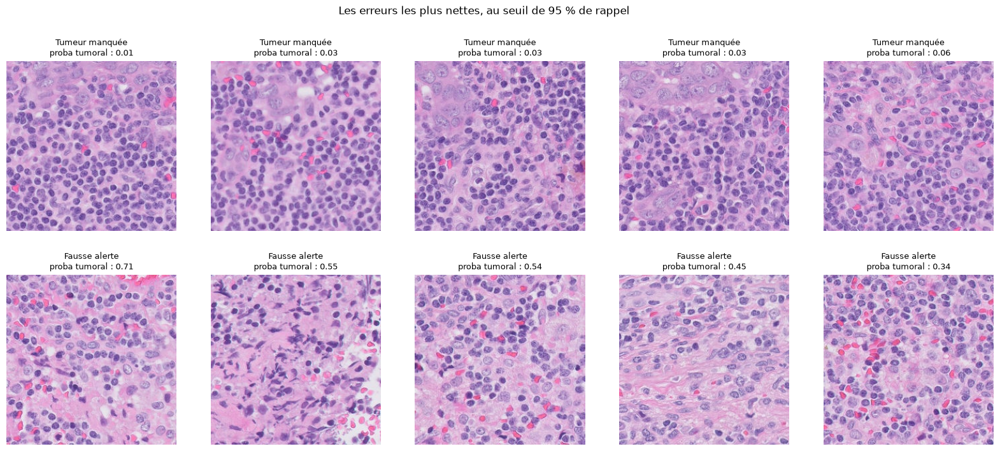

In [71]:
# Analyse des erreurs du modèle

predictions["vrai"] = (predictions["etiquette"] == "tumoral").astype(int)
predictions["predit"] = (predictions["proba_tumoral"] >= seuil_rappel_95).astype(int)

tumeurs_manquees = predictions[(predictions["vrai"] == 1) & (predictions["predit"] == 0)].sort_values("proba_tumoral") # On trie pour avoir les plus ratées (proba faible alors que tumorale)
fausses_alertes = predictions[(predictions["vrai"] == 0) & (predictions["predit"] == 1)].sort_values("proba_tumoral", ascending=False)
print("Tumeurs manquées :", len(tumeurs_manquees), "- Fausses alertes :", len(fausses_alertes))

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, (nom, erreurs) in enumerate([("Tumeur manquée", tumeurs_manquees), ("Fausse alerte", fausses_alertes)]):
    for j in range(5):
        axes[i, j].axis("off")
        if j < len(erreurs):
            p = erreurs.iloc[j]
            axes[i, j].imshow(Image.open(os.path.join(DOSSIER_PATCHS, p["fichier"])))
            axes[i, j].set_title(f"{nom}\nproba tumoral : {p['proba_tumoral']:.2f}", fontsize=9)
plt.suptitle("Les erreurs les plus nettes, au seuil de 95 % de rappel")
plt.show()

On observe que les tumeurs manquées semblent concerner des patchs avec plus de tissu sain que tumoral.

Pour les fausses alertes, on observe :
- Des patchs avec des globules rouge (en rose plus vif)
- Des patchs avec des zones assez désorganisées : on n'a pas que des lymphocytes bien organisés

In [ ]:
# Analyse des tumeurs manquées

display(tumeurs_manquees[["lame", "x", "y", "pct_tumeur", "pct_tumeur_centre", "proba_tumoral"]].head(10))

,lame,x,y,pct_tumeur,pct_tumeur_centre,proba_tumoral
304,patient_092_node_1,132096,76800,0.3736,0.2679,0.008676
380,patient_092_node_1,127488,79360,0.0440,0.0542,0.027861
156,patient_092_node_1,132608,76800,0.1613,0.0595,0.028986
20,patient_092_node_1,129024,78336,0.3450,0.1265,0.034802
177,patient_092_node_1,129536,77824,0.7178,0.9269,0.060994
110,patient_092_node_1,126464,77312,0.4663,0.5983,0.077782
316,patient_092_node_1,124928,75264,0.3772,0.2103,0.083415
4,patient_092_node_1,132608,76288,0.3759,0.2349,0.094810
314,patient_092_node_1,130048,77824,0.2253,0.1019,0.100224
182,patient_092_node_1,123392,71680,0.2287,0.0023,0.110523


Les patchs avec tumeurs manquées sont des patchs avec relativement "peu" de celulles tumorales en tous cas pas la majorité de la surface du patch, sauf dans un cas.

Il y a souvent moins de tumeur au centre donc à priori ce sont plutôt des tumeurs sur les bords des patchs.

Pour les patchs 177 et 110, les résultats sont étonnants car la probabilité est faible et le pourcentage de surface avec celulles tumorales élevé. Peut-être aussi de l'imprécision dans les annotations et masques ? Cf ci-dessous pour la lame patient_092_node_1.

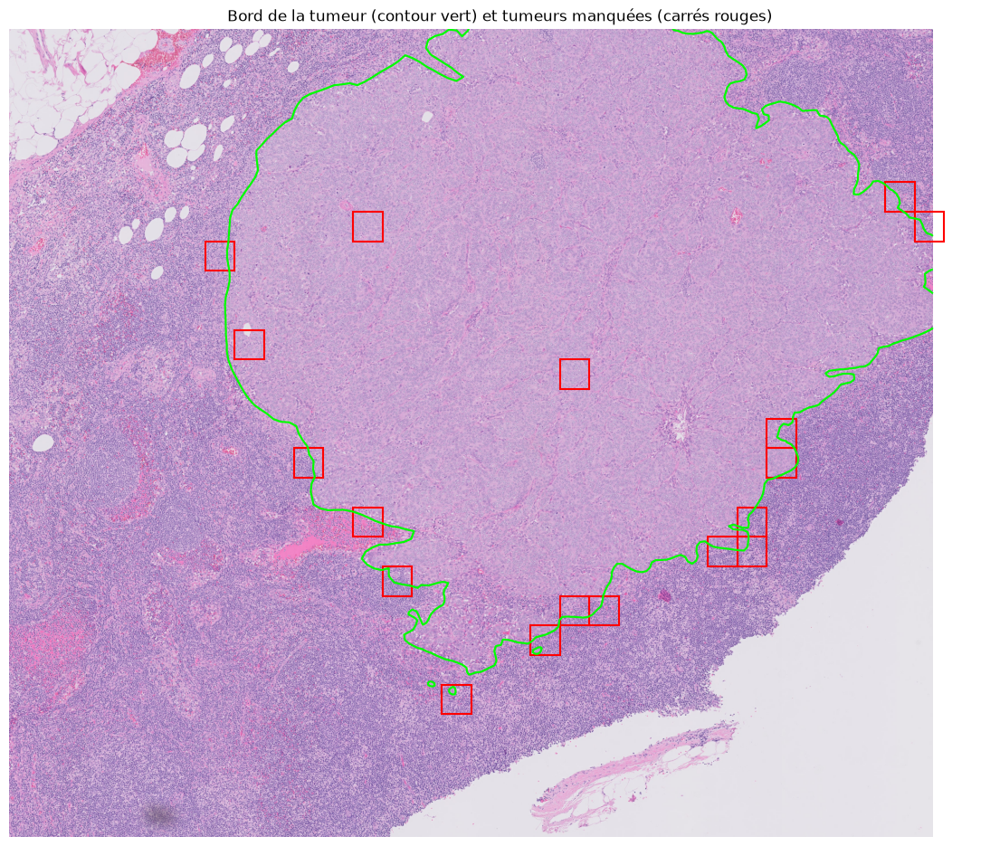

In [74]:
lame_092 = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, "patient_092_node_1.tif"))
masque_092 = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, "patient_092_node_1_mask.tif"))

x0, y0 = 120000, 68000 # Les tumeurs manquées sont entre x = 123 000 et 133 000 et y = 71 000 et 80 000.
largeur, hauteur = 16000, 14000 # On couvre cette zone
niveau = 2 # Niveau de lecture
facteur = int(lame_092.level_downsamples[niveau])
taille = (largeur // facteur, hauteur // facteur) # Taille de la zone en pixels du niveau 2 (read_region veut la taille dans le niveau lu).

zone_lame = lire_rgb(lame_092, (x0, y0), niveau, taille)
zone_masque = np.array(masque_092.read_region((x0, y0), niveau, taille))[:, :, 0]

fig, ax = plt.subplots(figsize=(14, 12))
ax.imshow(zone_lame)
ax.contour(zone_masque == 2, levels=[0.5], colors="lime", linewidths=1.5)
for _, p in tumeurs_manquees.iterrows():
    ax.add_patch(Rectangle(((p["x"] - x0) / facteur, (p["y"] - y0) / facteur), 512 / facteur, 512 / facteur,
                           fill=False, edgecolor="red", linewidth=1.5))
ax.set_title("Bord de la tumeur (contour vert) et tumeurs manquées (carrés rouges)")
ax.axis("off")
plt.show()

### 5.2. Etape 2 - Du patch à la lame

#### 5.2.1. Prédictions pour chaque patch de la lame de validation

On travaille sur la lame de validation, que le modèle n'a pas vu lors de son entrainement.

Il nous faut récupérer la classe prédite pour TOUS les patchs de cete lames. On ne va donc pas enregistrer tous les fichiers ici mais on fera une lecture à la volée : on lira le patch directement dans le fichier TIFF et on n'enregistrera que les prédictions dans un CSV.

On choisit un pas de 128 px ici (alors que 256 x pour l'entrainement du modèle) : 
- Cela nous permettra une meilleure précision sur la taille des zones tumorales : 
    - Avec un pas de 256 px, une case fait 128 µm. Une lésion de 150 µm et une de 250 µm peuvent toutes les deux occuper deux cases alors que l’une est une ITC et l’autre une micro-métastase.
    - Avec un pas de 128 px, une case fait 64 µm. On mesure plus finement.
- Cela nous permettra aussi de bien identifier une lésion coupée entre plusieurs patchs :
    - Sans chevauchement, une petite lésion peut tomber au coin de plusieurs patchs et elle n’est alors au centre d’aucun. Le modèle risque de la manquer car il a appris à juger le centre du patch (car on a choisi d'étiqueter les patchs en "tumoral" si pixel tumoral dans le centre du patch).
    - Avec un pas de 128 px = la taille de la zone centrale, les zones centrales se touchent et couvrent toute la lame. Chaque endroit du tissu est donc forcément au centre d’un patch.

In [75]:
PAS_LAME_ENTIERE = 128 # pas pour analyser une lame entière (zones centrales jointives)
NOM_LAME = "patient_092_node_1" # lame de validation
DOSSIER_LAMES_ENTIERES = os.path.join(DOSSIER_RESULTATS, "lames_entieres")
os.makedirs(DOSSIER_LAMES_ENTIERES, exist_ok=True)

# On recharge le classifieur depuis le fichier
classifieur = joblib.load(os.path.join(DOSSIER_RESULTATS, "classifieur.joblib"))

In [ ]:
def lister_patchs_lame_entiere(lame, pas=PAS_LAME_ENTIERE):
    tissu = masque_tissu(lame) # même détection du tissu qu'à l'entraînement
    facteur_patch = int(lame.level_downsamples[NIVEAU_PATCH])
    facteur_tissu = int(lame.level_downsamples[NIVEAU_TISSU])
    taille_0 = TAILLE_PATCH * facteur_patch
    pas_0 = pas * facteur_patch
    largeur_0, hauteur_0 = lame.dimensions

    # Positions de la grille
    positions_x = list(range(0, largeur_0 - taille_0 + 1, pas_0))
    positions_y = list(range(0, hauteur_0 - taille_0 + 1, pas_0))
    # + une dernière position collée au bord si la grille ne tombe pas pile dessus
    if positions_x[-1] != largeur_0 - taille_0:
        positions_x.append(largeur_0 - taille_0)
    if positions_y[-1] != hauteur_0 - taille_0:
        positions_y.append(hauteur_0 - taille_0)

    patchs = []
    for y in positions_y:
        for x in positions_x:
            zone_tissu = tissu[y // facteur_tissu:(y + taille_0) // facteur_tissu,
                               x // facteur_tissu:(x + taille_0) // facteur_tissu]
            pct_tissu = zone_tissu.mean()
            if pct_tissu >= SEUIL_TISSU:   # même règle des 25 %
                patchs.append({"x": x, "y": y, "pct_tissu": round(pct_tissu, 3)})
    return pd.DataFrame(patchs)

lame = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, NOM_LAME + ".tif"))
patchs_lame = lister_patchs_lame_entiere(lame)
print(len(patchs_lame), "patchs de tissu à prédire")

45073 patchs de tissu à prédire


On a redéfini ici une fonction car on change quelques petites choses :
- On ajoute si besoin une dernière position collée au bord droit et au bord bas de la lame (pour qu'aucune bande de tissu ne soit oubliée)
- On ne lit plus le masque officiel : c'est le modèle qui donnera la réponse
- On ne garde directement que les patchs avec au moins 25 % de tissu (même règle qu'à l'entraînement). Il n'y a plus de patchs « écartés car ambigus » car l'ambiguïté se repère avec le masque qu'on n'utilise plus
- La fonction reçoit la lame déjà ouverte (et plus son nom) car on l'ouvre maintenant une seule fois en dehors car le Dataset en a aussi besoin pour lire les patchs directement dans la lame

In [ ]:
# Nouveau Dataset (car les images ne sont plus des PNG utilisés mais sont lues directement dans le TIFF de la lame) et chargeur

class PatchsLameDataset(Dataset):
    def __init__(self, lame, tableau, transformation):
        self.lame = lame   # la lame ouverte avec OpenSlide
        self.tableau = tableau.reset_index(drop=True)
        self.transformation = transformation

    def __len__(self):
        return len(self.tableau)

    def __getitem__(self, i):
        ligne = self.tableau.iloc[i]
        position = (int(ligne["x"]), int(ligne["y"]))   # OpenSlide veut des entiers Python
        image = lire_rgb(self.lame, position, NIVEAU_PATCH, (TAILLE_PATCH, TAILLE_PATCH))
        return self.transformation(image), i   # pas d'étiquette : on renvoie le numéro du patch

jeu_lame = PatchsLameDataset(lame, patchs_lame, preparation)
chargeur_lame = DataLoader(jeu_lame, batch_size=64, shuffle=False, num_workers=0)

In [ ]:
# Essai sur 640 patchs (10 lots) pour estimer le temps

essai = PatchsLameDataset(lame, patchs_lame.iloc[:640], preparation)
debut = time.time()
X_essai, _ = extraire_caracteristiques(DataLoader(essai, batch_size=64, shuffle=False, num_workers=0))
duree = time.time() - debut
print(f"{duree:.1f} s pour 640 patchs, soit environ {duree / 640 * len(patchs_lame) / 60:.0f} min pour la lame entière")

4.2 s pour 640 patchs, soit environ 5 min pour la lame entière


In [ ]:
# Sur la lame entière

debut = time.time()
X_lame, numeros = extraire_caracteristiques(chargeur_lame)
print(f"Caractéristiques : {X_lame.shape}, en {(time.time() - debut) / 60:.1f} min")

assert (numeros == np.arange(len(patchs_lame))).all()   # vérifie que l'ordre est conservé

patchs_lame["proba_tumoral"] = classifieur.predict_proba(X_lame)[:, 1]
patchs_lame.to_csv(os.path.join(DOSSIER_LAMES_ENTIERES, NOM_LAME + "_predictions.csv"), index=False)

print(patchs_lame["proba_tumoral"].describe())
print("Patchs avec proba >= 0.5 :", (patchs_lame["proba_tumoral"] >= 0.5).sum())

Caractéristiques : (45073, 512), en 9.7 min
count    45073.000000
mean         0.073124
std          0.127952
min          0.000094
25%          0.009246
50%          0.024787
75%          0.068362
max          0.947407
Name: proba_tumoral, dtype: float64
Patchs avec proba >= 0.5 : 1279


#### 5.2.2. Carte de chaleur

On a maintenant pour chaque patch sa probabilité tumorale. Chaque patch représente un petit carré sur la lame et nous allons maintenant les rassembler dans une carte de chaleur :
- On rassemble les données qu'on a sur les patchs sous la forme d'un tableau 2D où chaque case correspond à un patch
- Les cases sans tissu restent vides
- Pour les cases avec tissu, on met dans la case la probabilité tumorale du patch et la couleur sera ajoutée à l'affichage (rouge quand probabilité élevée, orange quand moyenne, etc)
- Une case = un pixel sur la carte de chaleur (avec sa couleur en fonction de la probabilité)
- Comme on a choisi un pas de 128 px pour des patchs de 256 px, les patchs se chevauchent : chaque carré de 128 px de la lame est couvert par jusqu'à 4 patchs. Chaque pixel de la carte ne peut donc représenter que 128 × 128 px de la lame et on le posera sur la zone centrale du patch car c'est elle que le modèle a appris à juger. D'où le décalage de 64 px quand on superposera la carte à la lame.

In [ ]:
facteur_patch = int(lame.level_downsamples[NIVEAU_PATCH])
pas_0 = PAS_LAME_ENTIERE * facteur_patch # 256 : taille d'une case en pixels du niveau 0

# Numéro de colonne et de ligne de chaque patch (arrondi au-dessus pour les patchs du bord)
colonnes = np.ceil(patchs_lame["x"] / pas_0).astype(int).to_numpy() # np.ceil pour arrondir au dessus pour les patchs du bord
lignes = np.ceil(patchs_lame["y"] / pas_0).astype(int).to_numpy()

# Carte vide (NaN = pas de tissu), puis on écrit chaque probabilité dans sa case
carte = np.full((lignes.max() + 1, colonnes.max() + 1), np.nan) # Crée un tableau de la forme donnée, rempli partout avec la même valeur ici NaN
carte[lignes, colonnes] = patchs_lame["proba_tumoral"].to_numpy() # Numpy associe les trois listes position par position

print("Taille de la carte :", carte.shape, "(lignes, colonnes)")
print("Cases remplies :", np.count_nonzero(~np.isnan(carte)), "sur", len(patchs_lame), "patchs")

np.save(os.path.join(DOSSIER_LAMES_ENTIERES, NOM_LAME + "_carte.npy"), carte)

Taille de la carte : (351, 598) (lignes, colonnes)
Cases remplies : 45073 sur 45073 patchs


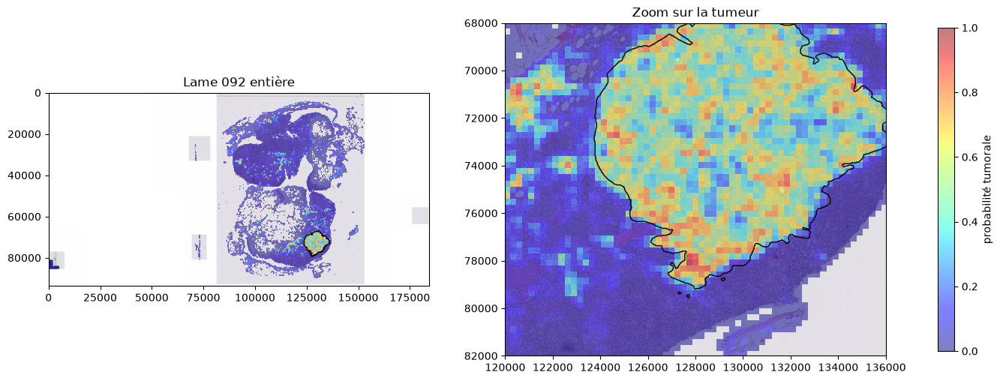

In [ ]:
NIVEAU_VUE = 5
facteur_vue = int(lame.level_downsamples[NIVEAU_VUE])
largeur_0, hauteur_0 = lame.dimensions

# La lame au niveau 5 (fond blanc)
vue_lame = lire_rgb(lame, (0, 0), NIVEAU_VUE, lame.level_dimensions[NIVEAU_VUE])

# Le masque officiel au niveau 5 pour tracer le contour de la tumeur (pour vérification seulement)
masque = openslide.OpenSlide(os.path.join(DOSSIER_MASQUES, NOM_LAME + "_mask.tif"))
tumeur_vue = np.array(masque.read_region((0, 0), NIVEAU_VUE, masque.level_dimensions[NIVEAU_VUE]))[:, :, 0] == 2
xs = (np.arange(tumeur_vue.shape[1]) + 0.5) * facteur_vue # centre de chaque pixel, en pixels du niveau 0
ys = (np.arange(tumeur_vue.shape[0]) + 0.5) * facteur_vue

# Où commence la carte : décalée de la moitié du bord du patch, pour tomber sur les zones centrales
decalage_0 = (TAILLE_PATCH - TAILLE_CENTRE) // 2 * facteur_patch # 128
etendue_carte = (decalage_0, decalage_0 + carte.shape[1] * pas_0, # gauche, droite
                 decalage_0 + carte.shape[0] * pas_0, decalage_0) # bas, haut

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax in axes:
    ax.imshow(vue_lame, extent=(0, largeur_0, hauteur_0, 0))
    image_carte = ax.imshow(carte, extent=etendue_carte, cmap="jet", vmin=0, vmax=1,
                            alpha=0.5, interpolation="nearest")
    ax.contour(xs, ys, tumeur_vue, levels=[0.5], colors="black", linewidths=1)
axes[0].set_title("Lame 092 entière")

# Zoom sur la tumeur (même zone que pour les erreurs)
x0, y0 = 120000, 68000
axes[1].set_xlim(x0, x0 + 16000)
axes[1].set_ylim(y0 + 14000, y0) # y à l'envers : le haut de l'image est en haut
axes[1].set_title("Zoom sur la tumeur")

fig.colorbar(image_carte, ax=axes, shrink=0.7, label="probabilité tumorale")
plt.show()

#### 5.2.3. De la carte de chaleur à la classe de la lame

Le principe :
- Chaque case devient tumorale si sa probabilité dépasse un seuil (on peut commencer avec celui optimisé sur le rappel mais à voir)
- On regroupe les cases voisines en lésions
- On nettoie c'est à dire qu'on comble les trous à l'intérieur d'une lésion (si on a raté des patchs tumoraux à lintérieur de la lésion donc complètement entourés de patchs tumoraux)
- On mesure chaque lésion
- On classe la lame d'après la plus grande lésion :
    - Pas de lésion : négative
    - Lésion de 0,2 mm au plus : ITC
    - Plus de 0,2 mm et jusqu’à 2 mm : micro-métastase
    - Plus de 2 mm : macro-métastase

On commence par choisir le seuil et on compare pour cela nos résultats avec plusieurs seuils comparés aux masques.

In [ ]:
# Le masque officiel

cote = pas_0 // facteur_vue # 8 : une case = 8 × 8 pixels du niveau 5
decal = decalage_0 // facteur_vue    # 4 : la zone centrale commence 4 pixels plus loin
nb_lignes, nb_colonnes = carte.shape

# On recopie le masque tumoral dans un tableau assez grand pour contenir toutes les cases
# (les cases du bord peuvent dépasser un peu le masque : ce qui dépasse reste à False)
grand = np.zeros((decal + nb_lignes * cote, decal + nb_colonnes * cote), dtype=bool)
h = min(grand.shape[0], tumeur_vue.shape[0])
w = min(grand.shape[1], tumeur_vue.shape[1])
grand[:h, :w] = tumeur_vue[:h, :w]

# On découpe la zone utile en blocs de 8 × 8 (un bloc = une case),
# et une case est « vraiment tumorale » si au moins un pixel de son bloc est tumoral
zone = grand[decal:decal + nb_lignes * cote, decal:decal + nb_colonnes * cote]
verite = zone.reshape(nb_lignes, cote, nb_colonnes, cote).any(axis=(1, 3))

tissu_carte = ~np.isnan(carte)   # True pour les cases avec tissu (celles qu'on a prédites)
verite = verite & tissu_carte    # on ne juge que les cases de tissu
print("Cases vraiment tumorales :", verite.sum(), "sur", tissu_carte.sum(), "cases de tissu")

Cases vraiment tumorales : 1530 sur 45073 cases de tissu


,seuil,cases prédites tumorales,VP (dans la tumeur),FP (fausses alertes),FN (tumeur manquée),rappel,précision
0,0.218,4039,1457,2582,73,0.952,0.361
1,0.500,1279,816,463,714,0.533,0.638
2,0.700,245,158,87,1372,0.103,0.645
3,0.800,53,32,21,1498,0.021,0.604
4,0.900,1,1,0,1529,0.001,1.000


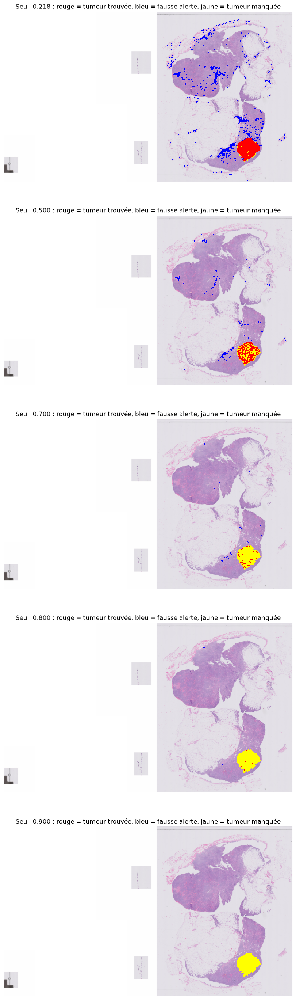

In [ ]:
# La comparaison

seuils_a_tester = [seuil_rappel_95, 0.5, 0.7, 0.8, 0.9]
probas = np.where(tissu_carte, carte, 0)   # NaN remplacés par 0 pour pouvoir comparer au seuil

resultats_seuils = []
cartes_erreurs = []
for seuil in seuils_a_tester:
    predit = tissu_carte & (probas >= seuil)   # cases prédites tumorales
    vp = (predit & verite).sum()               # tumorales trouvées
    fp = (predit & ~verite).sum()              # fausses alertes
    fn = (~predit & verite).sum()              # tumeur manquée
    resultats_seuils.append({"seuil": round(float(seuil), 3),
                             "cases prédites tumorales": predit.sum(),
                             "VP (dans la tumeur)": vp, "FP (fausses alertes)": fp, "FN (tumeur manquée)": fn,
                             "rappel": round(vp / (vp + fn), 3), "précision": round(vp / (vp + fp), 3)})
    # Carte des erreurs : 1 = VP, 2 = FP, 3 = FN, NaN = rien à afficher
    erreurs = np.full(carte.shape, np.nan)
    erreurs[predit & verite] = 1
    erreurs[predit & ~verite] = 2
    erreurs[~predit & verite] = 3
    cartes_erreurs.append(erreurs)

tableau_seuils = pd.DataFrame(resultats_seuils)
display(tableau_seuils)

couleurs = ListedColormap(["red", "blue", "yellow"])   # VP rouge, FP bleu, FN jaune
fig, axes = plt.subplots(len(seuils_a_tester), 1, figsize=(14, 7 * len(seuils_a_tester)))
for ax, seuil, erreurs in zip(axes, seuils_a_tester, cartes_erreurs):
    ax.imshow(vue_lame, extent=(0, largeur_0, hauteur_0, 0))
    ax.imshow(erreurs, extent=etendue_carte, cmap=couleurs, vmin=1, vmax=3, interpolation="nearest")
    ax.set_title(f"Seuil {seuil:.3f} : rouge = tumeur trouvée, bleu = fausse alerte, jaune = tumeur manquée")
    ax.axis("off")
plt.show()

In [ ]:
VOISINS_8 = np.ones((3, 3), dtype=int)   # les 8 voisins (diagonales comprises)
taille_case_um = pas_0 * float(lame.properties["openslide.mpp-x"])   # environ 62 µm
print(f"Une case = {taille_case_um:.1f} µm")

def trouver_lesions(carte, seuil_bas, seuil_haut):
    """Hystérésis + comblement des trous. Renvoie la carte des lésions numérotées."""
    probas = np.where(np.isnan(carte), 0, carte)
    bas = probas >= seuil_bas     # cases candidates
    haut = probas >= seuil_haut   # cases très sûres
    # 1) Groupes de cases candidates qui se touchent (8 voisins)
    groupes, _ = ndimage.label(bas, structure=VOISINS_8)
    # 2) On garde les groupes qui contiennent au moins une case très sûre
    numeros_gardes = np.unique(groupes[haut])
    numeros_gardes = numeros_gardes[numeros_gardes > 0]
    tumoral = np.isin(groupes, numeros_gardes)
    # 3) On comble les trous entourés de cases tumorales
    tumoral = ndimage.binary_fill_holes(tumoral)
    # 4) On numérote les lésions finales
    lesions, nb_lesions = ndimage.label(tumoral, structure=VOISINS_8)
    return lesions, nb_lesions

def plus_grande_dimension_um(masque_lesion):
    """Plus grande distance entre deux cases de la lésion en µm."""
    bord = masque_lesion & ~ndimage.binary_erosion(masque_lesion)   # seulement les cases du bord
    cases = np.argwhere(bord)   # coordonnées (ligne, colonne) des cases du bord
    if len(cases) == 1:
        return taille_case_um
    return (pdist(cases).max() + 1) * taille_case_um

def mesurer_lesions(lesions, verite):
    """Un tableau avec une ligne par lésion : nombre de cases, taille, vraie ou fausse."""
    lignes = []
    for numero, zone in enumerate(ndimage.find_objects(lesions), start=1):
        masque_lesion = lesions[zone] == numero
        lignes.append({"lesion": numero,
                       "nb_cases": int(masque_lesion.sum()),
                       "taille_um": plus_grande_dimension_um(masque_lesion),
                       "vraie": bool(verite[zone][masque_lesion].any())})
    return pd.DataFrame(lignes, columns=["lesion", "nb_cases", "taille_um", "vraie"])

def classer_lame(taille_max_um):
    if taille_max_um == 0:
        return "négative"
    if taille_max_um <= 200:
        return "ITC"
    if taille_max_um <= 2000:
        return "micro"
    return "macro"

Une case = 64.0 µm


In [90]:
SEUIL_LAME = 0.5
lesions, nb_lesions = trouver_lesions(carte, SEUIL_LAME, SEUIL_LAME)
tableau_lesions = mesurer_lesions(lesions, verite)
taille_max = tableau_lesions["taille_um"].max() if nb_lesions > 0 else 0
print(f"Plus grande lésion : {taille_max / 1000:.2f} mm - classe : {classer_lame(taille_max)}")

Plus grande lésion : 3.12 mm - classe : macro


### 5.3. Etape 3 - De la lame à la patiente

In [91]:
SEUIL_LAME = 0.5

def analyser_lame(nom_lame, seuil=SEUIL_LAME):
    """Toute la chaîne pour une lame : patchs → probabilités → carte → lésions → classe."""
    lame_a = openslide.OpenSlide(os.path.join(DOSSIER_IMAGES, nom_lame + ".tif"))
    chemin_csv = os.path.join(DOSSIER_LAMES_ENTIERES, nom_lame + "_predictions.csv")

    # 1) Probabilités de tous les patchs (on relit le CSV si la lame a déjà été prédite)
    if os.path.exists(chemin_csv):
        patchs = pd.read_csv(chemin_csv)
    else:
        debut = time.time()
        patchs = lister_patchs_lame_entiere(lame_a)
        chargeur = DataLoader(PatchsLameDataset(lame_a, patchs, preparation),
                              batch_size=64, shuffle=False, num_workers=0)
        X, numeros = extraire_caracteristiques(chargeur)
        assert (numeros == np.arange(len(patchs))).all()
        patchs["proba_tumoral"] = classifieur.predict_proba(X)[:, 1]
        patchs.to_csv(chemin_csv, index=False)
        print(f"{nom_lame} : {len(patchs)} patchs prédits en {(time.time() - debut) / 60:.1f} min")

    # 2) Carte de chaleur
    pas = PAS_LAME_ENTIERE * int(lame_a.level_downsamples[NIVEAU_PATCH])
    colonnes = np.ceil(patchs["x"] / pas).astype(int).to_numpy()
    lignes = np.ceil(patchs["y"] / pas).astype(int).to_numpy()
    carte_a = np.full((lignes.max() + 1, colonnes.max() + 1), np.nan)
    carte_a[lignes, colonnes] = patchs["proba_tumoral"].to_numpy()

    # 3) Lésions (seuil unique) et taille de chacune
    lesions_a, nb_lesions_a = trouver_lesions(carte_a, seuil, seuil)
    tailles = [plus_grande_dimension_um(lesions_a[zone] == numero)
               for numero, zone in enumerate(ndimage.find_objects(lesions_a), start=1)]
    taille_max = max(tailles, default=0)

    # 4) Classe de la lame
    resultat = {"lame": nom_lame, "nb patchs": len(patchs), "nb lésions": nb_lesions_a,
                "plus grande lésion (mm)": round(taille_max / 1000, 2),
                "classe prédite": classer_lame(taille_max)}
    return resultat, carte_a

def stade_pN(classes):
    """Règles de CAMELYON17 : du classement des ganglions au stade pN de la patiente."""
    nb_macro = classes.count("macro")
    nb_positifs = nb_macro + classes.count("micro")   # ganglions positifs = micro ou macro
    if nb_positifs == 0:
        return "pN0(i+)" if "ITC" in classes else "pN0"
    if nb_macro == 0:
        return "pN1mi"        # seulement des micro-métastases
    if nb_positifs <= 3:
        return "pN1"          # 1 à 3 ganglions positifs, dont au moins une macro
    return "pN2"              # 4 à 9 ganglions positifs, dont au moins une macro

In [92]:
selection = pd.read_csv("../data/prototype/selection_lames_prototype.csv")
lames_test = selection[selection["set"] == "test"]

resultats_test = []
cartes_test = {}
for _, ligne in lames_test.iterrows():
    resultat, carte_a = analyser_lame(ligne["lame"])
    resultat["vraie classe"] = ligne["classe"]
    resultats_test.append(resultat)
    cartes_test[ligne["lame"]] = carte_a

tableau_test = pd.DataFrame(resultats_test)
display(tableau_test)

stade_predit = stade_pN(list(tableau_test["classe prédite"]))
stade_vrai = stade_pN(list(tableau_test["vraie classe"]))
print(f"Stade pN prédit : {stade_predit}   |   vrai stade : {stade_vrai}")

patient_099_node_0 : 20971 patchs prédits en 4.5 min
patient_099_node_1 : 69076 patchs prédits en 14.7 min
patient_099_node_2 : 49349 patchs prédits en 14.8 min
patient_099_node_3 : 28652 patchs prédits en 7.5 min
patient_099_node_4 : 62678 patchs prédits en 16.3 min


,lame,nb patchs,nb lésions,plus grande lésion (mm),classe prédite,vraie classe
0,patient_099_node_0,20971,221,1.52,micro,negative
1,patient_099_node_1,69076,33,0.33,micro,negative
2,patient_099_node_2,49349,303,3.82,macro,negative
3,patient_099_node_3,28652,183,0.65,micro,negative
4,patient_099_node_4,62678,120,3.19,macro,macro


Stade pN prédit : pN2   |   vrai stade : pN1


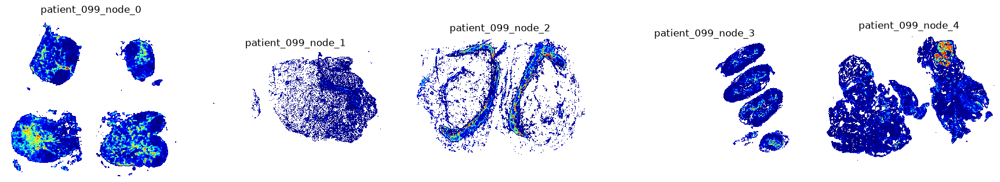

In [93]:
# Visualisation des 5 cartes

fig, axes = plt.subplots(1, len(cartes_test), figsize=(22, 6))
for ax, (nom, carte_a) in zip(axes, cartes_test.items()):
    ax.imshow(carte_a, cmap="jet", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(nom)
    ax.axis("off")
plt.show()

In [94]:
# Enregistrement des résultats (classes des lames de test + stade pN)

tableau_test.to_csv(os.path.join(DOSSIER_RESULTATS, "resultats_lames_test.csv"), index=False)

pd.DataFrame([{"patiente": 99, "stade prédit": stade_predit, "vrai stade": stade_vrai,
               "seuil": SEUIL_LAME}]).to_csv(os.path.join(DOSSIER_RESULTATS, "resultat_patiente_test.csv"), index=False)

print("Enregistré dans", DOSSIER_RESULTATS)

Enregistré dans ../data/prototype/resultats/strategie_1
